# **Jay Jagannath**

---



# **Import libraries and load the CSV**

In [180]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt      # for Vizualization

from scipy.stats import pearsonr     # for statistices corelation calculation

# Connect Google Drive to Colab
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/Climate Analysis West Bengal/Export_Data/WB_Annual_Climate_2000_2025.csv'
df = pd.read_csv(file_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [181]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Print Data Frame**

In [182]:
print(df.head()) # Only 5 records

   point_id  longitude   latitude  year  annual_min_temp_C  annual_max_temp_C  \
0         0  86.454785  23.479879  2000           7.364648          41.131494   
1         1  87.536680  23.075908  2000           8.757227          38.917825   
2         2  89.453581  26.174277  2000           9.535501          37.630212   
3         3  89.367415  26.349956  2000           9.269052          36.697290   
4         4  87.289156  21.871953  2000           9.602930          40.352533   

   annual_mean_temp_C  annual_precipitation_mm  annual_relative_humidity_pct  \
0           24.733728               930.001497                     65.298855   
1           25.293916              1298.261598                     71.541403   
2           23.937583              3368.055709                     74.341909   
3           23.686228              3090.336606                     72.085653   
4           25.754289              1221.950740                     73.145766   

   annual_wind_speed_m_s  annual

# **Dataset Information**

In [183]:
print("All Columns Name list: ")
print(df.columns.tolist())

print("\nDataset Shape:", df.shape)

All Columns Name list: 
['point_id', 'longitude', 'latitude', 'year', 'annual_min_temp_C', 'annual_max_temp_C', 'annual_mean_temp_C', 'annual_precipitation_mm', 'annual_relative_humidity_pct', 'annual_wind_speed_m_s', 'annual_wind_direction_deg', 'annual_evaporation_mm', 'annual_potential_evaporation_mm']

Dataset Shape: (77428, 13)


# **Check Missing values**

In [184]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
point_id                           0
longitude                          0
latitude                           0
year                               0
annual_min_temp_C                  0
annual_max_temp_C                  0
annual_mean_temp_C                 0
annual_precipitation_mm            0
annual_relative_humidity_pct       0
annual_wind_speed_m_s              0
annual_wind_direction_deg          0
annual_evaporation_mm              0
annual_potential_evaporation_mm    0
dtype: int64



# **Select year and temperature columns(min, max and mean)**

In [185]:
temp_column = ['year',
               'annual_min_temp_C',
               'annual_max_temp_C',
               'annual_mean_temp_C']

temp_df = df[temp_column].copy()

print(temp_df.head())

   year  annual_min_temp_C  annual_max_temp_C  annual_mean_temp_C
0  2000           7.364648          41.131494           24.733728
1  2000           8.757227          38.917825           25.293916
2  2000           9.535501          37.630212           23.937583
3  2000           9.269052          36.697290           23.686228
4  2000           9.602930          40.352533           25.754289


# **Yearwise min, max and mean temperature**

In [186]:
annual_temp = (
    temp_df
    .groupby("year")[temp_column]
    .mean()
    )

print(annual_temp, end= "")

        year  annual_min_temp_C  annual_max_temp_C  annual_mean_temp_C
year                                                                  
2000  2000.0           8.800511          38.446673           24.710332
2001  2001.0           7.853707          39.553712           24.707681
2002  2002.0           9.403002          39.285655           24.836599
2003  2003.0           7.683514          39.894364           24.620037
2004  2004.0           8.712330          41.087259           24.967907
2005  2005.0           9.333727          40.709562           25.209655
2006  2006.0           8.689431          38.800796           25.399913
2007  2007.0           9.036224          39.740914           24.992448
2008  2008.0           8.199781          39.182176           25.001307
2009  2009.0           9.583812          40.706099           25.664026
2010  2010.0           9.278367          41.072497           25.806495
2011  2011.0           8.111113          37.579832           24.882066
2012  

# **Calculate Long Term Average Temperature and Standerd diviation**

In [187]:
# Calculate average temperaturee for 2000 to 2025 period
mean_temp = annual_temp['annual_mean_temp_C'].mean()

# Calculate Standard Deviation.
std_temp = annual_temp['annual_mean_temp_C'].std()

print("Average Temperature:", round(mean_temp, 2))
print("Standard Deviation:", round(std_temp, 2))

Average Temperature: 25.1
Standard Deviation: 0.33


# **Prepare a Chart for Annual minimum, maximum and mean temperature**

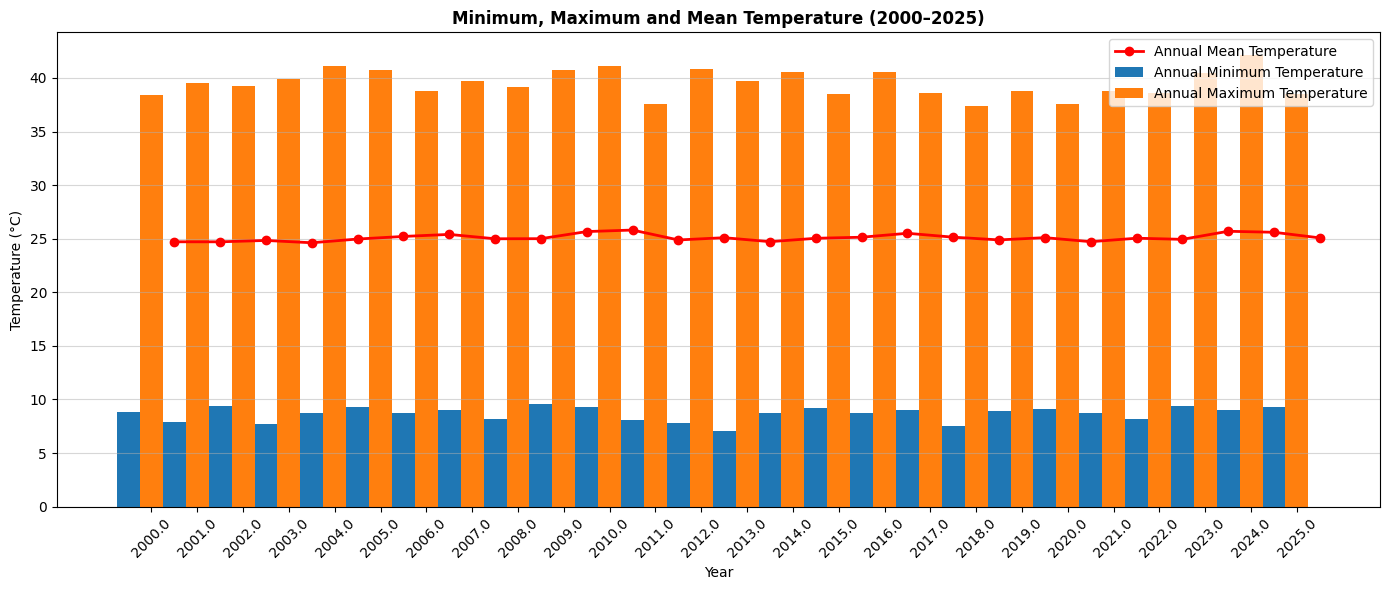

In [188]:
# Bar width and positions
bar_width = 0.5
x = np.arange(len(annual_temp['year']))

plt.figure(figsize=(14, 6))

# Annual Minimum Temperature
plt.bar(
    x - bar_width,
    annual_temp['annual_min_temp_C'],
    width=bar_width,
    label="Annual Minimum Temperature"
)

# Annual Maximum Temperature
plt.bar(
    x,
    annual_temp['annual_max_temp_C'],
    width=bar_width,
    label="Annual Maximum Temperature"
)

# Annual Mean Temperature
plt.plot(
    x + bar_width,
    annual_temp['annual_mean_temp_C'],
    marker='o',
    linewidth=2,
    color = 'red',
    label="Annual Mean Temperature"
)

# Title and labels
plt.title(
    "Minimum, Maximum and Mean Temperature (2000–2025)",
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Temperature (°C)")

# X-axis ticks
plt.xticks(x, annual_temp['year'], rotation=45)

# Grid and legend
plt.grid(axis='y', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# **Identify hottest and coolest years**


In [189]:
# Hottest data
hottest_index = annual_temp["annual_mean_temp_C"].idxmax()
hottest_year = annual_temp.loc[hottest_index, "year"]
hottest_temp = annual_temp.loc[hottest_index, "annual_mean_temp_C"]

# Coolest data
coolest_index = annual_temp["annual_mean_temp_C"].idxmin()
coolest_year = annual_temp.loc[coolest_index, "year"]
coolest_temp = annual_temp.loc[coolest_index, "annual_mean_temp_C"]

# Create Result DataFrame
temperature_extremes = pd.DataFrame({
    "Category": ["Hottest Year", "Coolest Year"],
    "Year": [round(hottest_year), round(coolest_year)],
    "Average Temperature (°C)": [
        round(hottest_temp, 2),
        round(coolest_temp, 2)
    ]
})

# print Result
display(temperature_extremes)

,Category,Year,Average Temperature (°C)
0,Hottest Year,2010,25.81
1,Coolest Year,2003,24.62


# **Calculate year-to-year temperature changes**

In [190]:
difference = annual_temp['annual_mean_temp_C'].diff()

annual_temp["temp_diff"] = difference

display(annual_temp[
    ['year',
    'annual_mean_temp_C',
    'temp_diff']
])
# For interactive result i use display() insted of print()

,year,annual_mean_temp_C,temp_diff
year,,,
2000,2000.0,24.710332,NaN
2001,2001.0,24.707681,-0.002651
2002,2002.0,24.836599,0.128918
2003,2003.0,24.620037,-0.216562
2004,2004.0,24.967907,0.347871
2005,2005.0,25.209655,0.241748
2006,2006.0,25.399913,0.190257
2007,2007.0,24.992448,-0.407465
2008,2008.0,25.001307,0.008860


# **Prepare a Chart for Year-to-year temperature changes**

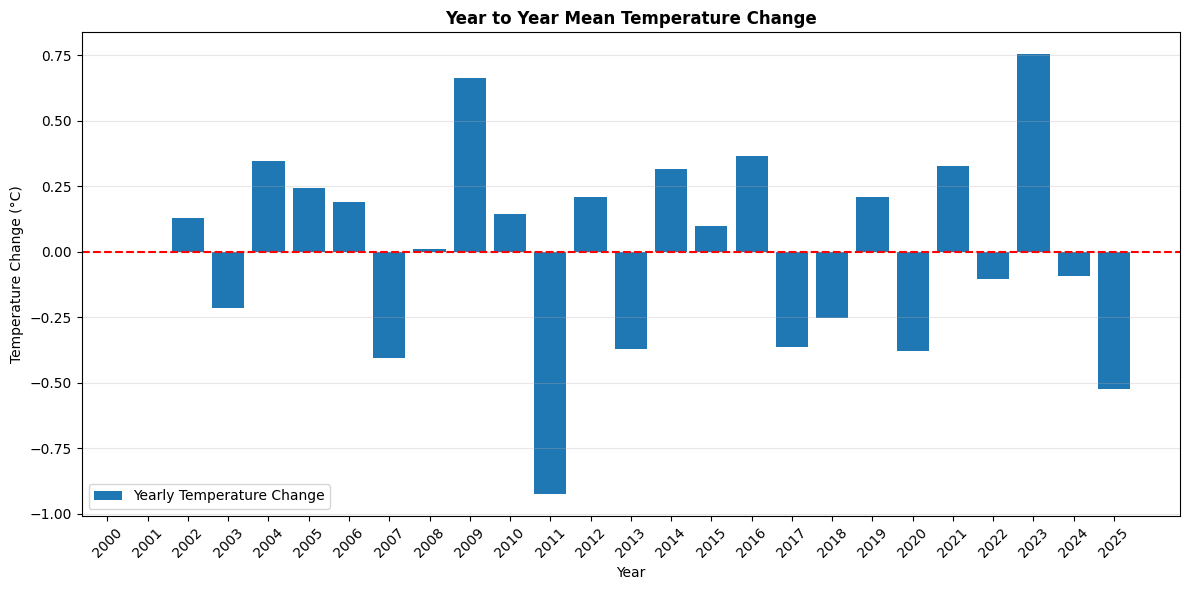

In [191]:
plt.figure(figsize=(12, 6))

plt.bar(
    annual_temp['year'],
    difference,
    label = "Yearly Temperature Change"
)

plt.axhline(y=0, linestyle="--", color = 'red')

plt.title("Year to Year Mean Temperature Change", fontweight = 'bold')
plt.xlabel("Year")
plt.ylabel("Temperature Change (°C)")

plt.xticks(annual_temp['year'], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# **Calculate the 5-year moving average**

In [192]:
moving_avg = (
    annual_temp['annual_mean_temp_C']
    .rolling(window=5)
    .mean()
)

annual_temp['annual_moving_avg_5y'] = moving_avg

print(annual_temp[['year', 'annual_mean_temp_C', 'annual_moving_avg_5y']])

        year  annual_mean_temp_C  annual_moving_avg_5y
year                                                  
2000  2000.0           24.710332                   NaN
2001  2001.0           24.707681                   NaN
2002  2002.0           24.836599                   NaN
2003  2003.0           24.620037                   NaN
2004  2004.0           24.967907             24.768511
2005  2005.0           25.209655             24.868376
2006  2006.0           25.399913             25.006822
2007  2007.0           24.992448             25.037992
2008  2008.0           25.001307             25.114246
2009  2009.0           25.664026             25.253470
2010  2010.0           25.806495             25.372838
2011  2011.0           24.882066             25.269269
2012  2012.0           25.092558             25.289291
2013  2013.0           24.722171             25.233463
2014  2014.0           25.037506             25.108159
2015  2015.0           25.137260             24.974312
2016  2016

# **Calculate the long-term temperature trend**

In [193]:
# Convert Year column to numpy
years = annual_temp['year'].to_numpy()                    # Independent variable
# Convert annual_mean_temp to numpy
mean_temp = annual_temp['annual_mean_temp_C'].to_numpy()   #Dependent variable

# Calculate linear trend
slope, intercept = np.polyfit(years, mean_temp, 1)

# Predicted temperature values
temp_trend = slope * years + intercept

# Calculate R squre
ss_total = np.sum(
    (mean_temp - np.mean(mean_temp))**2
)

ss_residual = np.sum(
    (mean_temp - temp_trend)** 2
)

r_sq = 1- (ss_residual/ss_total)

# Convert slope into change per decade
trend_per_decade = slope * 10

print("Temperature Trend:", round(trend_per_decade, 3), "°C per decade")
print("R-squared:", round(r_sq, 3))

if slope > 0:
    print("Overall Trend: Increasing Temperature")
elif slope < 0:
    print("Overall Trend: Decreasing Temperature")
else:
    print("Overall Trend: No Linear Change")

Temperature Trend: 0.135 °C per decade
R-squared: 0.097
Overall Trend: Increasing Temperature


# **Visualize annual temperature trends**

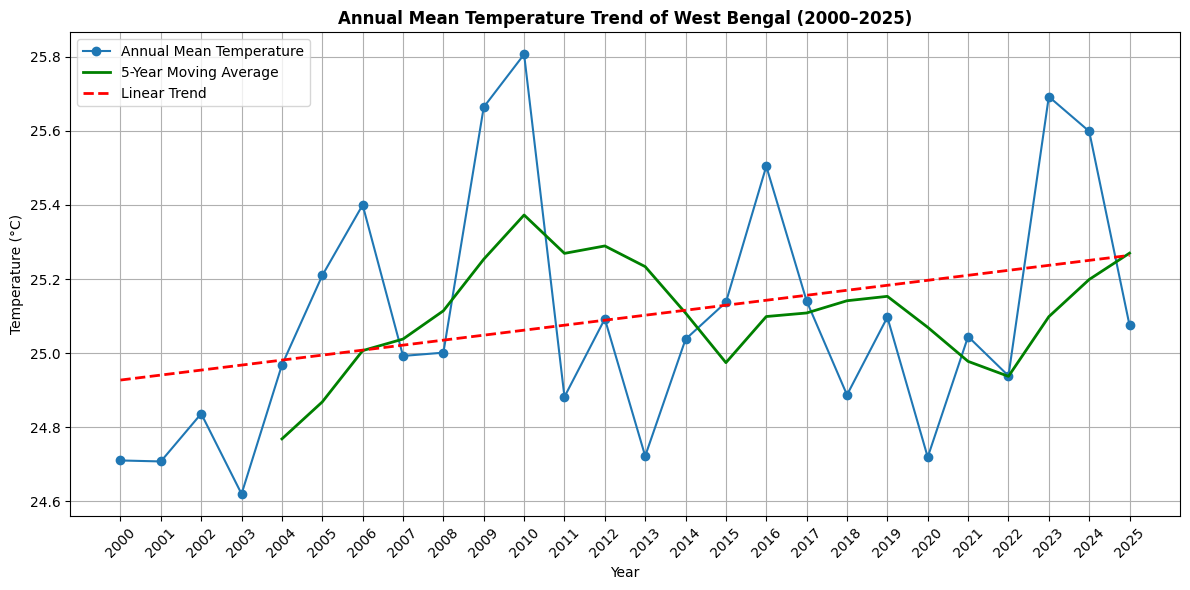

In [194]:
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    mean_temp,
    marker="o",
    label="Annual Mean Temperature"
)

plt.plot(
    years,
    moving_avg,
    linewidth=2,
    color = 'Green',
    label="5-Year Moving Average"
)

plt.plot(
    years,
    temp_trend,
    linestyle="--",
    linewidth=2,
    color = 'red',
    label="Linear Trend"
)

plt.title("Annual Mean Temperature Trend of West Bengal (2000–2025)", fontweight = 'bold')
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")

plt.xticks(years, rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# **Compare temperature between two periods**

**We will compare:**
 - **First period: 2000–2005**
 - **Recent period: 2020–2025**

In [195]:
first_period = (
    (annual_temp['year'] >= 2000) &
    (annual_temp['year'] <= 2005)
)

recent_period = (
    (annual_temp['year'] >= 2020) &
    (annual_temp['year'] <= 2025)
)

first_avg =annual_temp.loc[first_period, 'annual_mean_temp_C'].mean()
recent_avg =annual_temp.loc[recent_period, 'annual_mean_temp_C'].mean()
difference = recent_avg - first_avg

print("2000–2009 Average:", round(first_avg, 3), "°C")
print("2016–2025 Average:", round(recent_avg, 3), "°C")
print("Difference:", round(difference, 3), "°C")

2000–2009 Average: 24.842 °C
2016–2025 Average: 25.178 °C
Difference: 0.336 °C


# **Visualize Compare temperature between two periods**




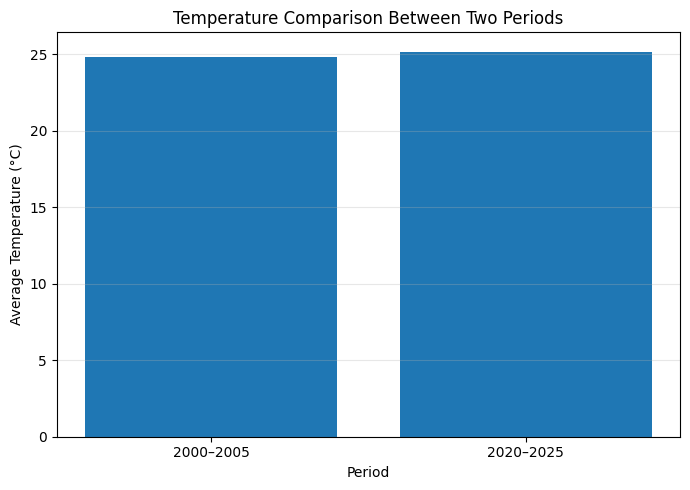

In [196]:
periods = ["2000–2005", "2020–2025"]
temperatures = [first_avg, recent_avg]

plt.figure(figsize=(7, 5))

plt.bar(periods, temperatures)

plt.title("Temperature Comparison Between Two Periods")
plt.xlabel("Period")
plt.ylabel("Average Temperature (°C)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **Annual Rainfall Variability Analysis of West Bengal (2000–2025)**

# **Select rainfall data**

In [197]:
rainfall_df = df[
    ['year', 'annual_precipitation_mm']
].copy()

display(rainfall_df.head())

,year,annual_precipitation_mm
0,2000,930.001497
1,2000,1298.261598
2,2000,3368.055709
3,2000,3090.336606
4,2000,1221.950740


# **Calculate yearly average rainfall**

In [198]:
annual_rainfall = (
    rainfall_df
    .groupby('year')['annual_precipitation_mm']
    .mean()
    .reset_index()
)

print(annual_rainfall)

    year  annual_precipitation_mm
0   2000              1785.945388
1   2001              1773.318464
2   2002              1982.743544
3   2003              1904.489272
4   2004              1816.449428
5   2005              1744.429285
6   2006              1545.337438
7   2007              2207.937505
8   2008              2028.719227
9   2009              1769.785317
10  2010              1638.762917
11  2011              2037.863208
12  2012              1620.518410
13  2013              1716.117171
14  2014              1645.818047
15  2015              2022.269539
16  2016              1838.471219
17  2017              2072.254697
18  2018              1672.404120
19  2019              1969.528422
20  2020              2069.049791
21  2021              1960.196124
22  2022              1505.797328
23  2023              1739.542328
24  2024              2034.656713
25  2025              2033.478875


# **Identify the wettest and driest years**

In [199]:
wettest_index = annual_rainfall["annual_precipitation_mm"].idxmax()
wettest_year = annual_rainfall.loc[wettest_index, "year"]
wettest_rainfall = annual_rainfall.loc[wettest_index, "annual_precipitation_mm"]

driest_index = annual_rainfall["annual_precipitation_mm"].idxmin()
driest_year = annual_rainfall.loc[driest_index, 'year']
driest_rainfall = annual_rainfall.loc[driest_index, 'annual_precipitation_mm']

print(f"Wettest Year {wettest_year} Average Rainfall : {round(wettest_rainfall, 2)}")
print(f"Driest Year {driest_year} Average Rainfall : {round(driest_rainfall, 2)}")

Wettest Year 2007 Average Rainfall : 2207.94
Driest Year 2022 Average Rainfall : 1505.8


# **Calculate long-term average rainfall and standard Deviation**

In [200]:
# Calculate Long-Term Average Rainfall
long_term_avg_rainfall = annual_rainfall['annual_precipitation_mm'].mean()

# Calculate Standard Deviation of rainfall
std_rainfall = annual_rainfall["annual_precipitation_mm"].std()

print(f"Long Term Average Rainfall :{round(long_term_avg_rainfall, 2)}")
print(f"Standard Deviation Of Rainfall :{round(std_rainfall, 2)}")

Long Term Average Rainfall :1851.38
Standard Deviation Of Rainfall :187.39


# **Calculate rainfall anomalies**

In [201]:
annual_rainfall['rainfall_anomalies'] = annual_rainfall['annual_precipitation_mm'] - long_term_avg_rainfall

# Add interpretation column
conditions = [
    annual_rainfall['rainfall_anomalies'] > 0,
    annual_rainfall['rainfall_anomalies'] < 0,
    annual_rainfall['rainfall_anomalies'] == 0
]

interpretations = [
    "Annual Rainfall was above the long-term average",
    "Annual Rainfall was below the long-term average",
    "Annual Rainfall was equal to the long-term average."
]

annual_rainfall['Interpretation'] = np.select(
    conditions,
    interpretations,
    default="Not Available"
)

display(annual_rainfall[
    ['year','annual_precipitation_mm', 'rainfall_anomalies', 'Interpretation']
].head(26))

,year,annual_precipitation_mm,rainfall_anomalies,Interpretation
0,2000,1785.945388,-65.434758,Annual Rainfall was below the long-term average
1,2001,1773.318464,-78.061681,Annual Rainfall was below the long-term average
2,2002,1982.743544,131.363399,Annual Rainfall was above the long-term average
3,2003,1904.489272,53.109127,Annual Rainfall was above the long-term average
4,2004,1816.449428,-34.930717,Annual Rainfall was below the long-term average
5,2005,1744.429285,-106.950860,Annual Rainfall was below the long-term average
6,2006,1545.337438,-306.042707,Annual Rainfall was below the long-term average
7,2007,2207.937505,356.557360,Annual Rainfall was above the long-term average
8,2008,2028.719227,177.339082,Annual Rainfall was above the long-term average
9,2009,1769.785317,-81.594829,Annual Rainfall was below the long-term average


# **Visualize rainfall anomalies**

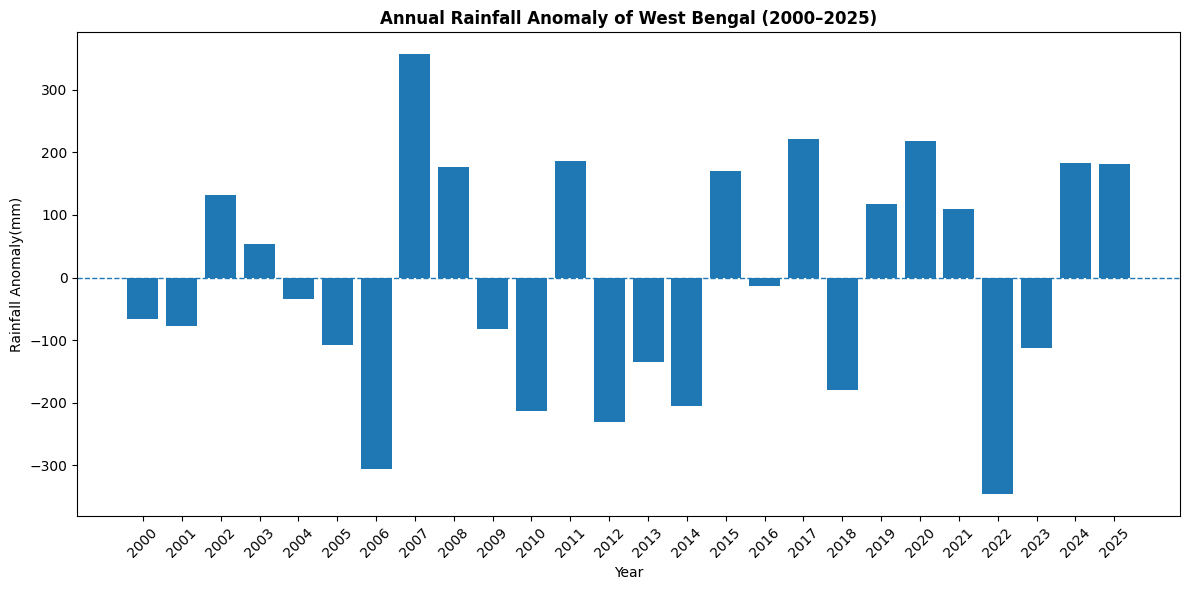

In [202]:
plt.figure(figsize=(12, 6))

plt.bar(
    annual_rainfall['year'],
    annual_rainfall['rainfall_anomalies'],
)

plt.axhline(
    y = 0,
    linestyle ="--",
    linewidth = 1
)

plt.title("Annual Rainfall Anomaly of West Bengal (2000–2025)",fontweight = "bold")
plt.xlabel("Year")
plt.ylabel("Rainfall Anomaly(mm)")

plt.xticks(annual_rainfall['year'], rotation=45)

plt.tight_layout()
plt.show()


# **Identify wet and dry years**

In [203]:
annual_rainfall["category"] = np.where(
    annual_rainfall['rainfall_anomalies'] > 0,
    "Wet Year", "Dry Year"
)

display(
    annual_rainfall[
        ["year",
        "annual_precipitation_mm",
        "rainfall_anomalies",
        "category"]
    ]
)

,year,annual_precipitation_mm,rainfall_anomalies,category
0,2000,1785.945388,-65.434758,Dry Year
1,2001,1773.318464,-78.061681,Dry Year
2,2002,1982.743544,131.363399,Wet Year
3,2003,1904.489272,53.109127,Wet Year
4,2004,1816.449428,-34.930717,Dry Year
5,2005,1744.429285,-106.950860,Dry Year
6,2006,1545.337438,-306.042707,Dry Year
7,2007,2207.937505,356.557360,Wet Year
8,2008,2028.719227,177.339082,Wet Year
9,2009,1769.785317,-81.594829,Dry Year


# **Count the number of wet and dry years**

In [204]:
print(annual_rainfall['category'].value_counts())

category
Dry Year    14
Wet Year    12
Name: count, dtype: int64


# **Calculate year-to-year rainfall changes**

In [205]:
annual_rainfall["rainfall_changes"] = annual_rainfall['annual_precipitation_mm'].diff()

display(annual_rainfall[
    ['year',
     'annual_precipitation_mm',
     'rainfall_changes']
])

,year,annual_precipitation_mm,rainfall_changes
0,2000,1785.945388,NaN
1,2001,1773.318464,-12.626924
2,2002,1982.743544,209.425080
3,2003,1904.489272,-78.254272
4,2004,1816.449428,-88.039844
5,2005,1744.429285,-72.020143
6,2006,1545.337438,-199.091847
7,2007,2207.937505,662.600067
8,2008,2028.719227,-179.218277
9,2009,1769.785317,-258.933911


# **Calculate percentage change**


In [206]:
annual_rainfall["rainfall_changes_percent"] = (
    round(annual_rainfall["annual_precipitation_mm"].pct_change(),4) * 100
)

display(
    annual_rainfall[
        ["year", "annual_precipitation_mm", "rainfall_changes","rainfall_changes_percent"]
    ]
)

,year,annual_precipitation_mm,rainfall_changes,rainfall_changes_percent
0,2000,1785.945388,NaN,NaN
1,2001,1773.318464,-12.626924,-0.71
2,2002,1982.743544,209.425080,11.81
3,2003,1904.489272,-78.254272,-3.95
4,2004,1816.449428,-88.039844,-4.62
5,2005,1744.429285,-72.020143,-3.96
6,2006,1545.337438,-199.091847,-11.41
7,2007,2207.937505,662.600067,42.88
8,2008,2028.719227,-179.218277,-8.12
9,2009,1769.785317,-258.933911,-12.76


# **Visualize Year-to-year rainfall change**

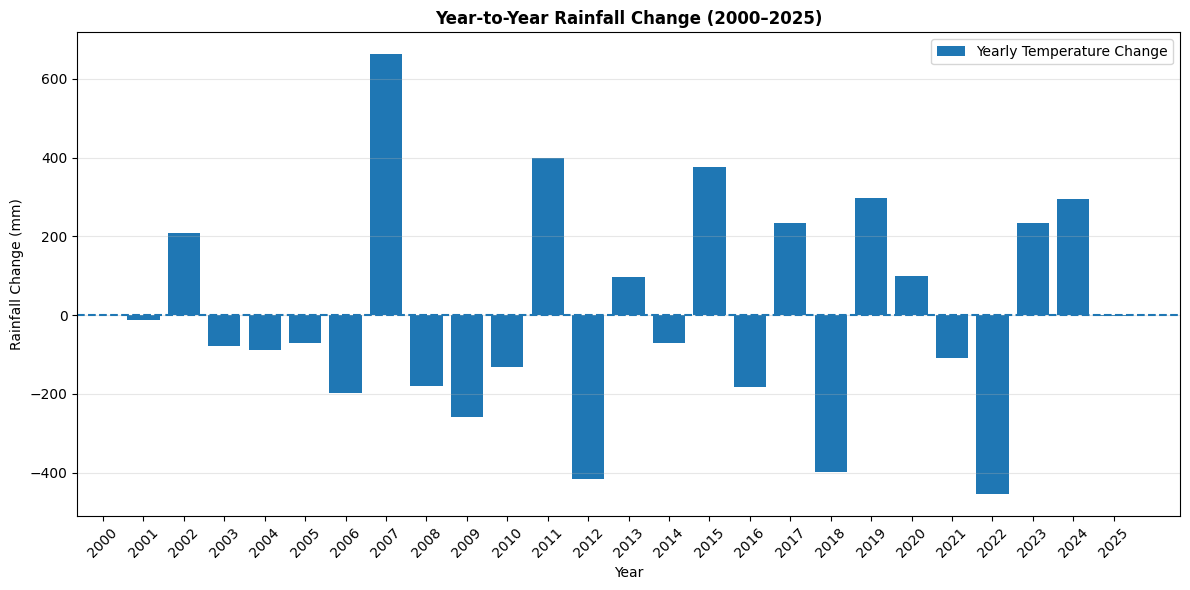

In [207]:
plt.figure(figsize = (12, 6))

plt.bar(
    annual_rainfall['year'],
    annual_rainfall['rainfall_changes'],
    label = "Yearly Temperature Change"
)

plt.axhline(
    y = 0,
    linestyle = '--'
)

plt.title("Year-to-Year Rainfall Change (2000–2025)",
          fontweight = 'bold')

plt.xlabel("Year")
plt.ylabel("Rainfall Change (mm)")

plt.xticks(annual_rainfall['year'], rotation = 45)
plt.grid(axis='y', alpha = 0.3)
plt.tight_layout()
plt.legend()
plt.show()

# **Calculate 5-year moving average**

In [208]:
annual_rainfall['rainfall_moving_avg_5y'] = (
    annual_rainfall['annual_precipitation_mm']
    .rolling(window=5)
    .mean()
)

print(annual_rainfall[
    ['year',
     'annual_precipitation_mm',
     'rainfall_moving_avg_5y']
])

    year  annual_precipitation_mm  rainfall_moving_avg_5y
0   2000              1785.945388                     NaN
1   2001              1773.318464                     NaN
2   2002              1982.743544                     NaN
3   2003              1904.489272                     NaN
4   2004              1816.449428             1852.589219
5   2005              1744.429285             1844.285999
6   2006              1545.337438             1798.689793
7   2007              2207.937505             1843.728586
8   2008              2028.719227             1868.574577
9   2009              1769.785317             1859.241754
10  2010              1638.762917             1838.108481
11  2011              2037.863208             1936.613635
12  2012              1620.518410             1819.129816
13  2013              1716.117171             1756.609405
14  2014              1645.818047             1731.815951
15  2015              2022.269539             1808.517275
16  2016      

# **Visualize Annual rainfall and 5-year moving average**

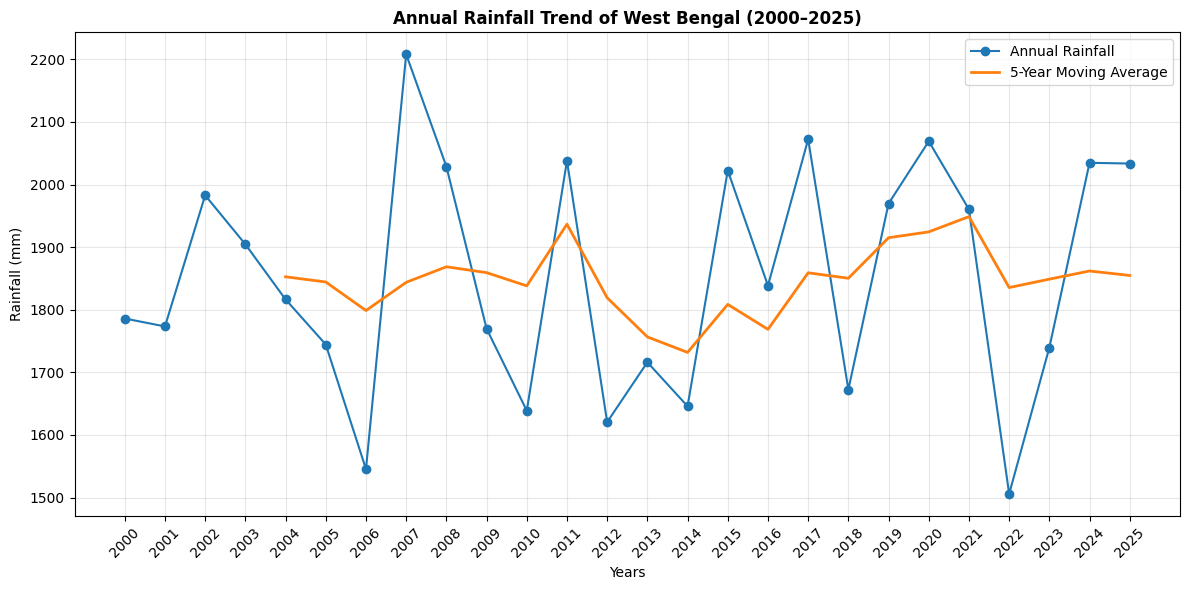

In [209]:
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    annual_rainfall['annual_precipitation_mm'],
    marker = 'o',
    label = "Annual Rainfall"
)

plt.plot(
    years,
    annual_rainfall['rainfall_moving_avg_5y'],
    linewidth = 2,
    label = "5-Year Moving Average"
)

plt.title(
    "Annual Rainfall Trend of West Bengal (2000–2025)",
    fontweight="bold"
)

plt.xlabel("Years")
plt.ylabel("Rainfall (mm)")



plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# **Calculate long-term rainfall trend using NumPy**

In [210]:
# Independent Veriable
years = annual_rainfall['year'].to_numpy()

# Dependent Veriable
rainfall = annual_rainfall['annual_precipitation_mm'].to_numpy()

# linear Regression
slope, intercept = np.polyfit(
    years,
    rainfall,
    1
)

# predicted rainfall
rainfall_trend = slope * years + intercept

# Calculate R squre
ss_total = np.sum(
    (rainfall - np.mean(rainfall))**2)

ss_residual = np.sum(
    (rainfall - rainfall_trend)**2)

r_sq = 1 - (ss_residual/ss_total)

# Rainfall trend per decade
trend_per_decade = slope * 10


print("Rainfall Trend:", round(trend_per_decade, 2), "mm/decade")
print("R-squared:", round(r_sq, 3))

if slope > 0:
    print("Overall Trend: Increasing Rainfall")
elif slope < 0:
    print("Overall Trend: Decreasing Rainfall")
else:
    print("Overall Trend: No Linear Change")

Rainfall Trend: 27.91 mm/decade
R-squared: 0.013
Overall Trend: Increasing Rainfall


# **Visualize Annual rainfall with linear trend**

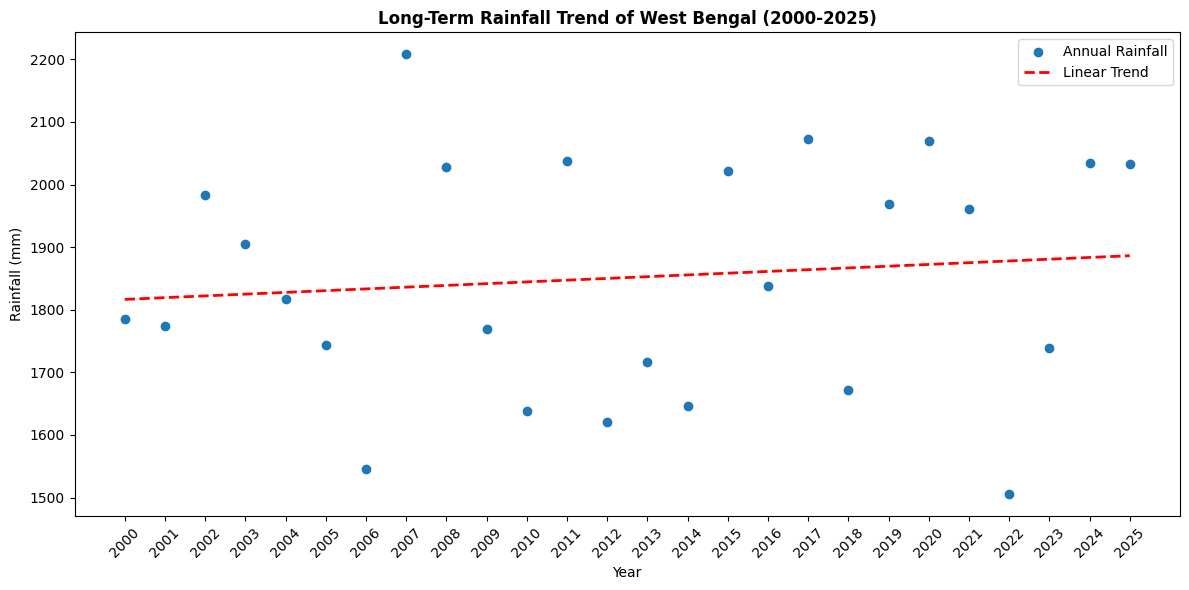

In [211]:
from matplotlib.lines import lineStyles
plt.figure(figsize=(12, 6))

plt.scatter(
    years,
    rainfall,
    label = "Annual Rainfall"
)

plt.plot(
    years,
    rainfall_trend,
    linewidth = 2,
    linestyle = '--',
    color = 'red',
    label = "Linear Trend"
)

plt.title(
    "Long-Term Rainfall Trend of West Bengal (2000-2025)",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")

plt.xticks(years, rotation = 45)
plt.legend()
plt.tight_layout()
plt.show()

# **Compare rainfall between two periods**

1.   **First period: 2000–2005**
2.   **Recent period: 2020–2025**







In [212]:
first_rainfall_period = (annual_rainfall[
    (annual_rainfall['year'] >= 2000) &
    (annual_rainfall['year'] <= 2005)]
)

recent_rainfall_period = (
    annual_rainfall[
        (annual_rainfall['year'] >= 2020) &
        (annual_rainfall['year'] <= 2025)
    ]
)

first_rainfall_avg = (
    first_rainfall_period['annual_precipitation_mm'].mean()
)

recent_rainfall_avg = (
    recent_rainfall_period['annual_precipitation_mm'].mean()
)

rainfall_difference = recent_rainfall_avg - first_rainfall_avg

percentage_difference = (rainfall_difference/first_rainfall_avg) * 100

print(f"2000 to 2005 period rainfall average: {first_rainfall_avg}")
print(f"2020 to 2025 period rainfall agerage: {recent_rainfall_avg}")
print(f"Difference rainfall between two period: {round(rainfall_difference, 2)}")
print(f"Difference percentage between two period: {round(percentage_difference, 2)}")


2000 to 2005 period rainfall average: 1834.5625634599974
2020 to 2025 period rainfall agerage: 1890.4535261386645
Difference rainfall between two period: 55.89
Difference percentage between two period: 3.05


# **Visualize the comparison**

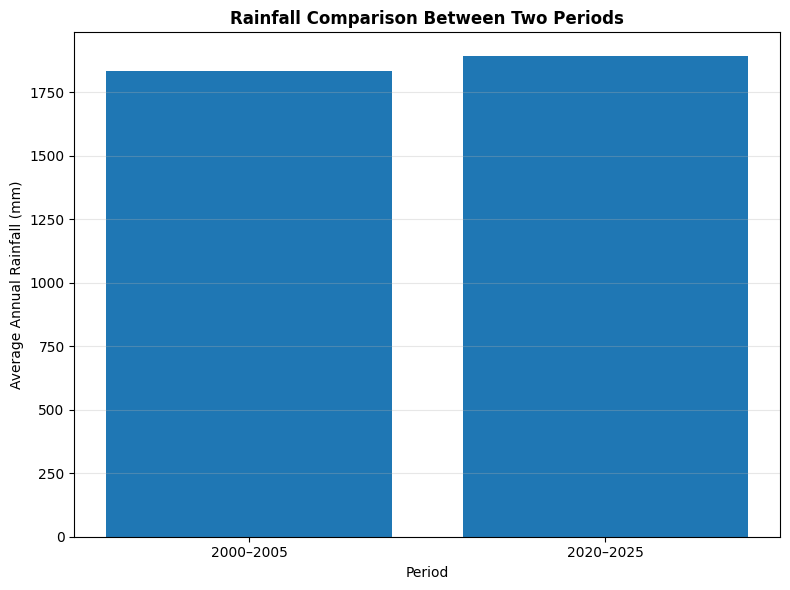

In [213]:
periods = ["2000–2005", "2020–2025"]

rainfall_values = [
    first_rainfall_avg,
    recent_rainfall_avg
]

plt.figure(figsize=(8, 6))

plt.bar(periods, rainfall_values)

plt.title(
    "Rainfall Comparison Between Two Periods",
    fontweight="bold"
)

plt.xlabel("Period")
plt.ylabel("Average Annual Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **Calculate Pearson correlation coefficient between temparature and rainfall of 2025**

In [214]:
# select 2025 data
data_2025 = df.loc[df['year']==2025]

# Calculate corelation and p_value
correlation, p_value = pearsonr(
    data_2025['annual_mean_temp_C'],
    data_2025['annual_precipitation_mm']
)

# Calculate trend line
x = data_2025['annual_mean_temp_C'].to_numpy()
y = data_2025['annual_precipitation_mm'].to_numpy()

slope, intercept = np.polyfit(x, y, 1)

trend_line = slope * x + intercept

# print all statistical value and interpretation
print(f"Pearson Correlation Coefficient: {round(correlation, 3)}")

if correlation == 1:
    interpretation = "Perfect Positive Correlation"

elif correlation >= 0.70:
    interpretation = "Strong Positive Correlation"

elif correlation >= 0.30:
    interpretation = "Moderate Positive Correlation"

elif correlation > 0:
    interpretation = "Weak Positive Correlation"

elif correlation == 0:
    interpretation = "No Linear Correlation"

elif correlation > -0.30:
    interpretation = "Weak Negative Correlation"

elif correlation > -0.70:
    interpretation = "Moderate Negative Correlation"

elif correlation > -1:
    interpretation = "Strong Negative Correlation"

else:
    interpretation = "Perfect Negative Correlation"

print("Interpretation:", interpretation)


print(f"P-value: {p_value}")

if p_value < 0.05:
    significance = "Statistically Significant"
else:
    significance = "Not Statistically Significant"

print("Statistical Significance:", significance)


Pearson Correlation Coefficient: -0.747
Interpretation: Strong Negative Correlation
P-value: 0.0
Statistical Significance: Statistically Significant


# **Visualize correlation between temperature and rainfall with trend line**

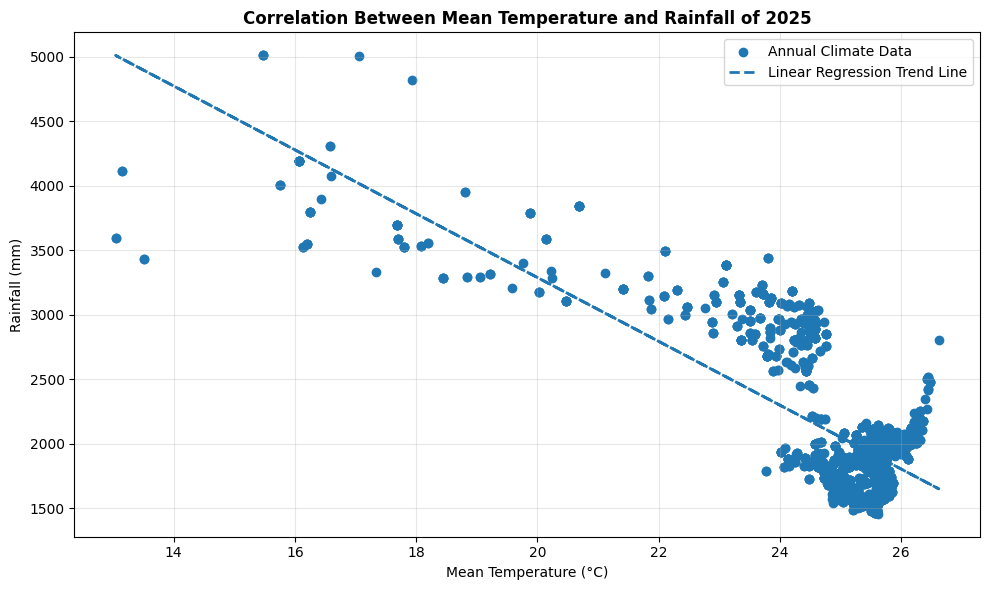

In [215]:
plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    marker='o',
    label='Annual Climate Data'
)

plt.plot(
    x,
    trend_line,
    linestyle='--',
    linewidth=2,
    label='Linear Regression Trend Line'
)

plt.title(
    "Correlation Between Mean Temperature and Rainfall of 2025",
    fontweight='bold'
)

plt.xlabel("Mean Temperature (°C)")
plt.ylabel("Rainfall (mm)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **Annual Relative Humidity Analysis – West Bengal (2000–2025)**

# **Select Relative humidity data**

In [216]:
rh_column = ['year',
             'annual_relative_humidity_pct']

relative_humidity_df= df[rh_column].copy()

display(relative_humidity_df)

,year,annual_relative_humidity_pct
0,2000,65.298855
1,2000,71.541403
2,2000,74.341909
3,2000,72.085653
4,2000,73.145766
...,...,...
77423,2025,73.428386
77424,2025,78.040349
77425,2025,70.882055
77426,2025,74.279536


# **Calculate average relative humidity for each year**

In [217]:
annual_rh = (
    relative_humidity_df
    .groupby('year')['annual_relative_humidity_pct']
    .mean()
    .reset_index()
)


display(annual_rh)


,year,annual_relative_humidity_pct
0,2000,71.990022
1,2001,72.436242
2,2002,73.671324
3,2003,74.806931
4,2004,71.704509
5,2005,71.946374
6,2006,71.096933
7,2007,72.832641
8,2008,73.030021
9,2009,69.942221


# **Identify high and low humidity years**

In [218]:
high_rh_index = annual_rh['annual_relative_humidity_pct'].idxmax()
high_rh_year = annual_rh.loc[high_rh_index, 'year']
high_rh = annual_rh.loc[high_rh_index, 'annual_relative_humidity_pct']

low_rh_index = annual_rh['annual_relative_humidity_pct'].idxmin()
low_rh_year = annual_rh.loc[low_rh_index, 'year']
low_rh = annual_rh.loc[low_rh_index, 'annual_relative_humidity_pct']

print(f"High relative humidity in the year {high_rh_year} was {high_rh}%")
print(f"Low relative humidity in the year {low_rh_year} was {low_rh}%")


High relative humidity in the year 2020 was 75.16879766018197%
Low relative humidity in the year 2009 was 69.94222134097652%


# **Calculate long-term average humidity & Standard Deviation**

In [219]:
avg_humidity = np.mean(
    annual_rh['annual_relative_humidity_pct']
)

std_rh = np.std(
    annual_rh['annual_relative_humidity_pct']
)

print(f"2000 to 2025 avarage relative humidity: {round(avg_humidity, 2)}%")
print(f"Standard Deviation of relative humidity: {round(std_rh, 2)}%")


2000 to 2025 avarage relative humidity: 72.78%
Standard Deviation of relative humidity: 1.39%


# **Calculate humidity anomalies**

In [220]:
annual_rh['rh_anomaly'] = (
    annual_rh['annual_relative_humidity_pct'] - avg_humidity
)

display(
    annual_rh[
     ['year',
      'annual_relative_humidity_pct',
      'rh_anomaly']
    ]
)


,year,annual_relative_humidity_pct,rh_anomaly
0,2000,71.990022,-0.793943
1,2001,72.436242,-0.347723
2,2002,73.671324,0.887359
3,2003,74.806931,2.022966
4,2004,71.704509,-1.079456
5,2005,71.946374,-0.837591
6,2006,71.096933,-1.687032
7,2007,72.832641,0.048676
8,2008,73.030021,0.246056
9,2009,69.942221,-2.841744


# **Visualize humidity anomalies**

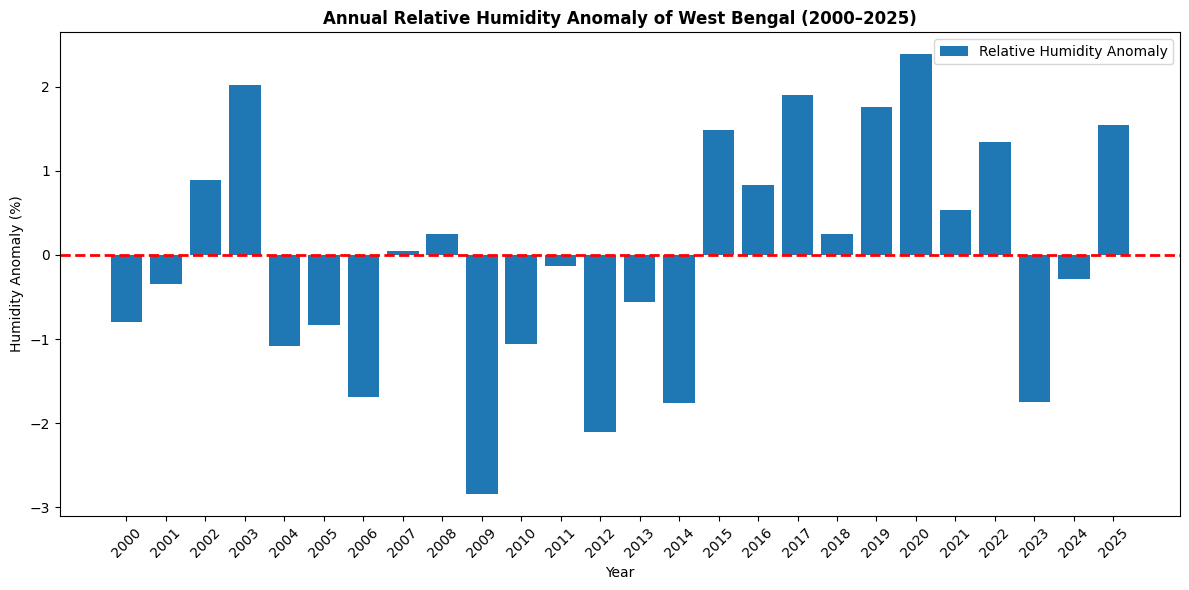

In [221]:
plt.figure(figsize=(12, 6))

plt.bar(
    annual_rh['year'],
    annual_rh['rh_anomaly'],
    label = "Relative Humidity Anomaly"
)

plt.axhline(
    y=0,
    linewidth = 2,
    linestyle = '--',
    color = "red"
)

plt.title(
    "Annual Relative Humidity Anomaly of West Bengal (2000–2025)",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel("Humidity Anomaly (%)")

plt.xticks(annual_rh['year'], rotation = 45)

plt.legend()
plt.tight_layout()
plt.show()


# **Calculate year-to-year humidity changes**

In [222]:
annual_rh['humidity_chenge'] = (
    annual_rh['annual_relative_humidity_pct'].diff()
)

display(annual_rh[
    ['year',
     'annual_relative_humidity_pct',
     'humidity_chenge']
])

,year,annual_relative_humidity_pct,humidity_chenge
0,2000,71.990022,NaN
1,2001,72.436242,0.446220
2,2002,73.671324,1.235082
3,2003,74.806931,1.135607
4,2004,71.704509,-3.102421
5,2005,71.946374,0.241864
6,2006,71.096933,-0.849441
7,2007,72.832641,1.735708
8,2008,73.030021,0.197380
9,2009,69.942221,-3.087800


# **Visualize year-to-year humidity changes**

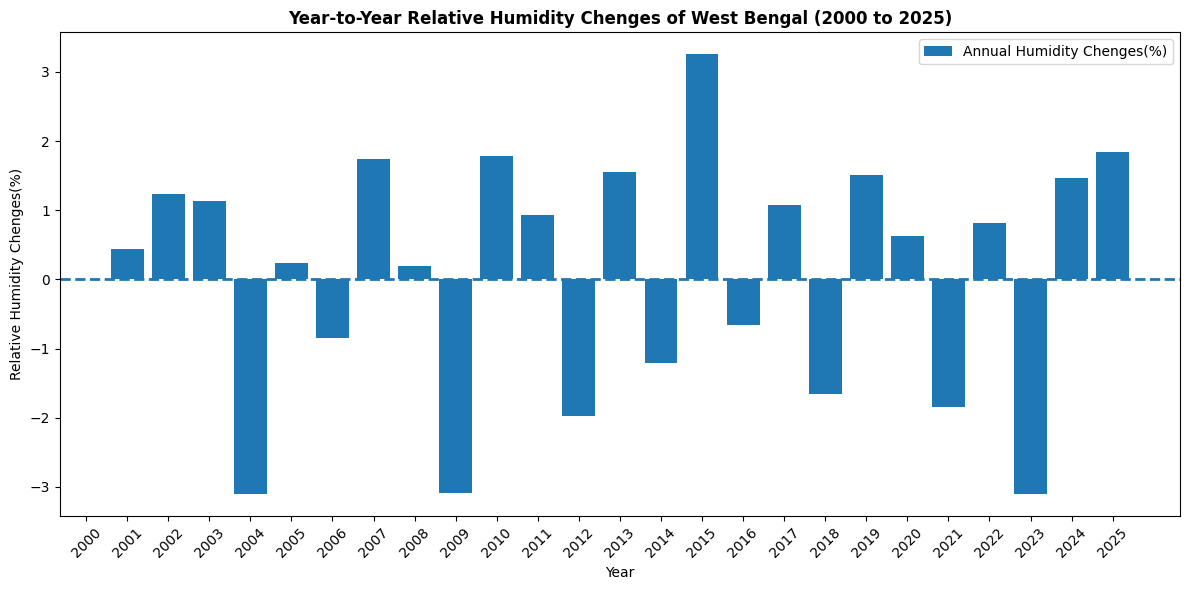

In [223]:
plt.figure(figsize=(12, 6))

plt.bar(
    annual_rh['year'],
    annual_rh['humidity_chenge'],
    label = "Annual Humidity Chenges(%)"
)

plt.axhline(
    y = 0,
    linestyle = '--',
    linewidth = 2
)

plt.title(
    "Year-to-Year Relative Humidity Chenges of West Bengal (2000 to 2025)",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel("Relative Humidity Chenges(%)")

plt.xticks(annual_rh['year'], rotation = 45)
plt.tight_layout()
plt.legend()
plt.show()

# **Calculate 5-year moving average**

In [224]:
annual_rh['5y_moving_avg_rh'] =(
    annual_rh['annual_relative_humidity_pct']
    .rolling(window= 5)
    .mean()
)

display(annual_rh[
    ['year',
     'annual_relative_humidity_pct',
     '5y_moving_avg_rh']
])

,year,annual_relative_humidity_pct,5y_moving_avg_rh
0,2000,71.990022,NaN
1,2001,72.436242,NaN
2,2002,73.671324,NaN
3,2003,74.806931,NaN
4,2004,71.704509,72.921806
5,2005,71.946374,72.913076
6,2006,71.096933,72.645214
7,2007,72.832641,72.477478
8,2008,73.030021,72.122096
9,2009,69.942221,71.769638


# **Annual relative humidity and 5-year moving average**

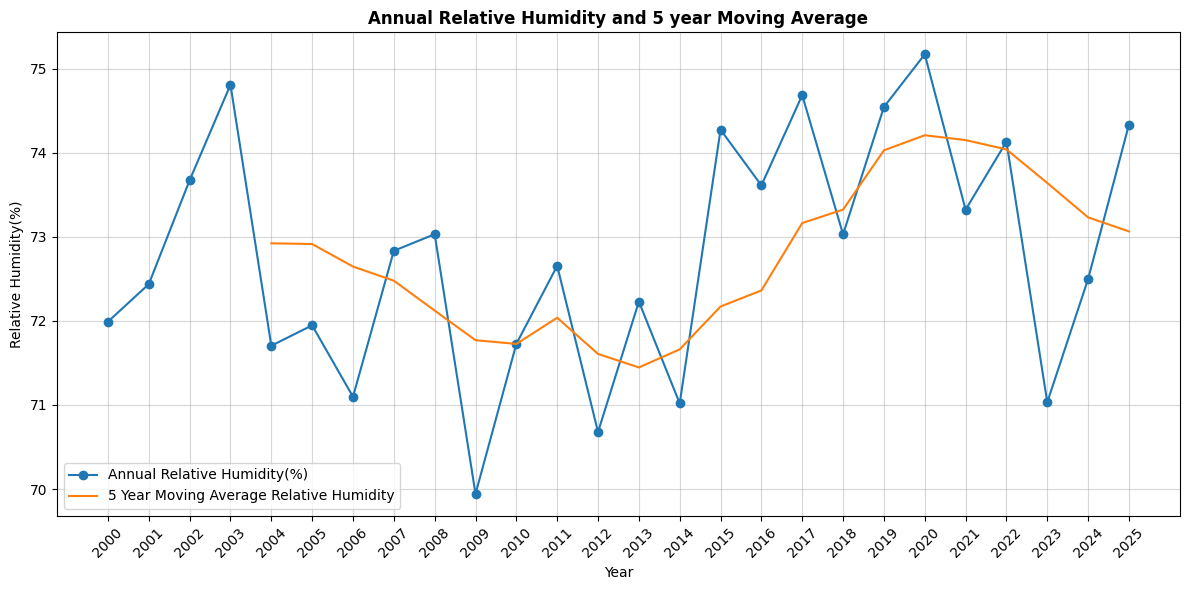

In [225]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_rh['year'],
    annual_rh['annual_relative_humidity_pct'],
    marker= 'o',
    label = "Annual Relative Humidity(%)"
)

plt.plot(
    annual_rh['year'],
    annual_rh['5y_moving_avg_rh'],
    label = "5 Year Moving Average Relative Humidity"
)

plt.title(
    "Annual Relative Humidity and 5 year Moving Average",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel("Relative Humidity(%)")


plt.xticks(annual_rh['year'], rotation = 45)
plt.grid(True, alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()


# **Calculate long-term humidity trend using NumPy**

In [226]:
# Independent Veriable
years = annual_rh['year'].to_numpy()

# Dependent Veriable
rh = annual_rh['annual_relative_humidity_pct'].to_numpy()

# Calculate Linear regression
slope, intercept = np.polyfit(years, rh, 1)

# Predicted relative humidity value
trend_rh = slope * years + intercept

# Calculate R-squared
ss_total = np.sum((rh - np.mean(rh))** 2)

ss_residual = np.sum((rh - trend_rh)**2)

r_sq = 1- (ss_residual/ss_total)

# Humidity Trend Per Decade
trend_per_decade = slope * 10


print(f"Humidity Trend: {round(trend_per_decade, 3)} % per decade")

print("R-squared:", round(r_sq, 3))

if slope > 0:
    print("Overall Trend: Increasing Relative Humidity")
elif slope < 0:
    print("Overall Trend: Decreasing Relative Humidity")
else:
    print("Overall Trend: No Linear Change")

Humidity Trend: 0.562 % per decade
R-squared: 0.092
Overall Trend: Increasing Relative Humidity


# **Visualize Annual Relative Humidity with Linear Trend**

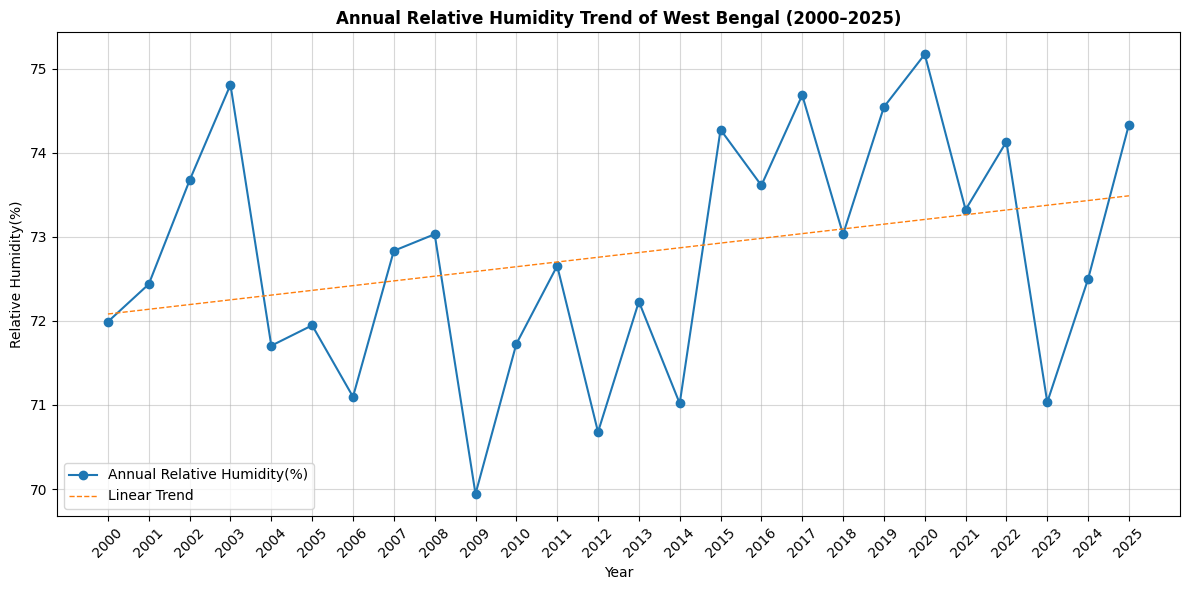

In [227]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_rh['year'],
    annual_rh['annual_relative_humidity_pct'],
    marker= 'o',
    label = "Annual Relative Humidity(%)"
)

plt.plot(
    annual_rh['year'],
    trend_rh,
    linestyle = '--',
    linewidth = 1,
    label = "Linear Trend"
)

plt.title(
    "Annual Relative Humidity Trend of West Bengal (2000–2025)",
    fontweight = 'bold'
)

plt.xlabel('Year')
plt.ylabel("Relative Humidity(%)")

plt.xticks(annual_rh['year'], rotation = 45)
plt.grid(True, alpha = 0.5)
plt.legend()
plt.tight_layout()
plt.show()

# **Compare relative humidity between two periods**


1.   First period: 2000–2009
2.   Recent period: 2016–2025




In [228]:
first_period = annual_rh[(annual_rh['year'] >= 2000) &
                         (annual_rh['year'] <= 2009)
]

recent_period = annual_rh[(annual_rh['year'] >= 2016) &
                          (annual_rh['year'] <= 2025)
]

first_avg = first_period["annual_relative_humidity_pct"].mean()

recent_avg = recent_period['annual_relative_humidity_pct'].mean()

difference = recent_avg - first_avg

print(f"2000–2009 Relative Humidity Average:{round(first_avg, 2)} %")
print(f"2016–2025 Relative Humidity Average: {round(recent_avg, 2)} %")
print(f"Difference of Relative Humidity between two period: {round(difference, 2)} %")


2000–2009 Relative Humidity Average:72.35 %
2016–2025 Relative Humidity Average: 73.63 %
Difference of Relative Humidity between two period: 1.29 %


# **Average Relative Humidity across all points**

In [229]:
location_humidity = (
    df.groupby(["longitude", "latitude"])
    ["annual_relative_humidity_pct"]
    .mean()
    .reset_index()
)

display(location_humidity)


,longitude,latitude,annual_relative_humidity_pct
0,85.869773,23.471460,66.033541
1,85.870735,23.295148,65.554905
2,85.871080,23.299250,65.554905
3,85.884123,23.441006,66.033541
4,85.894703,23.382470,65.857415
...,...,...,...
2973,89.825822,26.560529,75.969122
2974,89.833564,26.679865,78.659634
2975,89.848250,26.399029,76.058348
2976,89.857966,26.455175,74.730834


# **Identify the 10 most humid locations**

In [230]:
highest_rh_location = (
    location_humidity.nlargest(10, 'annual_relative_humidity_pct')
)

display(highest_rh_location)

,longitude,latitude,annual_relative_humidity_pct
1651,88.151790,27.109738,86.609821
1662,88.156871,27.038945,86.098219
1685,88.175919,27.011846,86.098219
1706,88.188606,27.026800,86.098219
1719,88.197285,27.012193,86.098219
1429,88.018237,27.191755,85.999018
1462,88.039027,27.138203,85.999018
1491,88.054558,27.051192,85.121146
1559,88.096964,27.094380,85.121146
1791,88.235633,27.040070,84.403834


# **Identify the 10 least humid locations**

In [231]:
smallest_rh_location = (
    location_humidity.nsmallest(10, 'annual_relative_humidity_pct')
)

display(smallest_rh_location)

,longitude,latitude,annual_relative_humidity_pct
22,86.011029,23.482102,65.549735
25,86.025278,23.407836,65.549735
34,86.078104,23.434324,65.549735
1,85.870735,23.295148,65.554905
2,85.871080,23.299250,65.554905
42,86.121249,23.482281,65.669035
44,86.127878,23.421769,65.669035
48,86.146794,23.425659,65.669035
20,86.004950,23.366607,65.683818
23,86.013983,23.372022,65.683818


# **Calculate Pearson correlation coefficient between temparature and relative humidity**

In [232]:
# Calculate Corelation and p_value
correlation, p_value = pearsonr(
    annual_temp['annual_mean_temp_C'],
    annual_rh['annual_relative_humidity_pct']
)

# calculate trend line
temp = annual_temp['annual_mean_temp_C'].to_numpy()
rh = annual_rh['annual_relative_humidity_pct'].to_numpy()

slope, intercept = np.polyfit(temp, rh, 1)

trend_line = slope * temp + intercept



# print all statistical value and interpretation
print(f"Pearson Correlation Coefficient: {round(correlation, 3)}")

if correlation == 1:
    interpretation = "Perfect Positive Correlation"

elif correlation >= 0.70:
    interpretation = "Strong Positive Correlation"

elif correlation >= 0.30:
    interpretation = "Moderate Positive Correlation"

elif correlation > 0:
    interpretation = "Weak Positive Correlation"

elif correlation == 0:
    interpretation = "No Linear Correlation"

elif correlation > -0.30:
    interpretation = "Weak Negative Correlation"

elif correlation > -0.70:
    interpretation = "Moderate Negative Correlation"

elif correlation > -1:
    interpretation = "Strong Negative Correlation"

else:
    interpretation = "Perfect Negative Correlation"

print("Interpretation:", interpretation)


print(f"P-value: {p_value}")

if p_value < 0.05:
    significance = "Statistically Significant"
else:
    significance = "Not Statistically Significant"

print("Statistical Significance:", significance)

Pearson Correlation Coefficient: -0.441
Interpretation: Moderate Negative Correlation
P-value: 0.023979131507580322
Statistical Significance: Statistically Significant


# **Visualize temperature-humidity relationship**

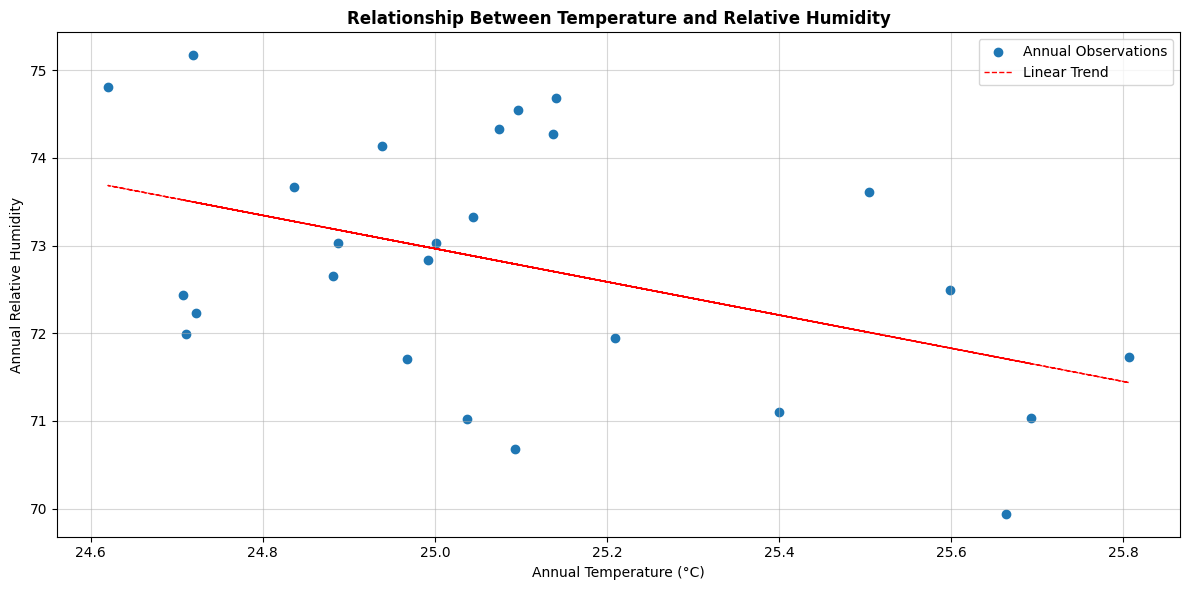

In [233]:
plt.figure(figsize=(12, 6))

plt.scatter(
    temp,
    rh,
    label = "Annual Observations"
)

plt.plot(
    temp,
    trend_line,
    label = "Linear Trend",
    linestyle = '--',
    color = 'red',
    linewidth = 1
)

plt.title(
    "Relationship Between Temperature and Relative Humidity",
    fontweight = 'bold'
)

plt.xlabel("Annual Temperature (°C)")
plt.ylabel("Annual Relative Humidity")

plt.grid(True, alpha= 0.5)
plt.tight_layout()
plt.legend()
plt.show()


# **Evaporation and Potential Evaporation Analysis of West Bengal (2000–2025)**


# **Select evaporation variables**

In [234]:
evap_df = df[
    ['year',
    'annual_evaporation_mm',
    'annual_potential_evaporation_mm']
].copy()

print(evap_df)

       year  annual_evaporation_mm  annual_potential_evaporation_mm
0      2000             935.155419                      2498.468287
1      2000            1030.400276                      2117.805414
2      2000             925.637645                      1895.449467
3      2000             899.477260                      1764.328547
4      2000            1080.629801                      2446.206696
...     ...                    ...                              ...
77423  2025            1025.754847                      1993.566364
77424  2025             941.862790                      1654.867470
77425  2025             949.273231                      2124.851234
77426  2025             946.780497                      2229.098909
77427  2025             869.970639                      2303.892680

[77428 rows x 3 columns]


# **Calculate yearly average evaporation**

In [235]:
annual_evap = (
    evap_df.groupby('year')[
        ['annual_evaporation_mm',
         'annual_potential_evaporation_mm']
        ].mean()
        .reset_index()
)

display(annual_evap)

,year,annual_evaporation_mm,annual_potential_evaporation_mm
0,2000,982.190603,2241.483957
1,2001,937.337934,2175.050698
2,2002,983.268855,2148.962113
3,2003,969.991306,2133.742580
4,2004,929.547063,2274.071871
5,2005,963.250165,2338.602621
6,2006,958.368896,2320.496888
7,2007,975.407428,2208.286204
8,2008,947.778361,2182.375740
9,2009,923.773483,2374.198873


# **Visualize yearly average evaporation and potential_evaporation**

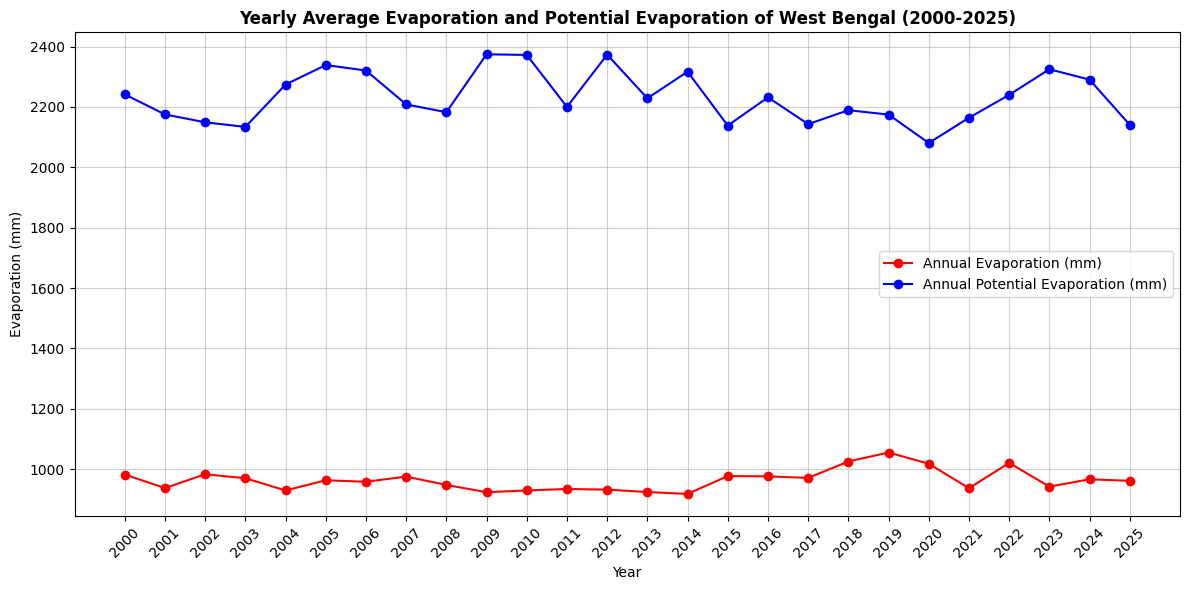

In [236]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_evap['year'],
    annual_evap['annual_evaporation_mm'],
    label = 'Annual Evaporation (mm)',
    marker = 'o',
    color = 'red'
)

plt.plot(
    annual_evap['year'],
    annual_evap['annual_potential_evaporation_mm'],
    label = 'Annual Potential Evaporation (mm)',
    marker = 'o',
    color = 'blue'
)

plt.title(
    "Yearly Average Evaporation and Potential Evaporation of West Bengal (2000-2025)",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel('Evaporation (mm)')

plt.xticks(annual_evap['year'], rotation = 45)
plt.tight_layout()
plt.grid(True, alpha = 0.6)
plt.legend()
plt.show()

# **Identify the highest and lowest evaporation years**

In [237]:
# Highest Evaporation Index
highest_evap_index = annual_evap['annual_evaporation_mm'].idxmax()

# Highest Evaporation Year
highest_evap_year = annual_evap.loc[highest_evap_index, 'year']

# Highest Evaporation Value
highest_evap = annual_evap.loc[highest_evap_index, 'annual_evaporation_mm']

# Lowest Evaporation Index
lowest_evap_index = annual_evap['annual_evaporation_mm'].idxmin()

# Lowest Evaporation year
lowest_evap_year = annual_evap.loc[lowest_evap_index, 'year']

# Lowest Evaporation value
lowest_evap = annual_evap.loc[lowest_evap_index, 'annual_evaporation_mm']


print("Highest Evaporation Year:", highest_evap_year)
print("Highest Evaporation:", round(highest_evap, 2), "mm")

print("\nLowest Evaporation Year:", lowest_evap_year)
print("Lowest Evaporation:", round(lowest_evap, 2), "mm")


Highest Evaporation Year: 2019
Highest Evaporation: 1055.21 mm

Lowest Evaporation Year: 2014
Lowest Evaporation: 918.05 mm


# **Calculate evaporation difference**

In [238]:
annual_evap['evaporation_difference'] = annual_evap['annual_potential_evaporation_mm']- annual_evap['annual_evaporation_mm']

display(
    annual_evap[
        ['year',
         'annual_evaporation_mm',
         'annual_potential_evaporation_mm',
         'evaporation_difference']
    ]
)

,year,annual_evaporation_mm,annual_potential_evaporation_mm,evaporation_difference
0,2000,982.190603,2241.483957,1259.293353
1,2001,937.337934,2175.050698,1237.712765
2,2002,983.268855,2148.962113,1165.693258
3,2003,969.991306,2133.742580,1163.751274
4,2004,929.547063,2274.071871,1344.524807
5,2005,963.250165,2338.602621,1375.352456
6,2006,958.368896,2320.496888,1362.127993
7,2007,975.407428,2208.286204,1232.878776
8,2008,947.778361,2182.375740,1234.597378
9,2009,923.773483,2374.198873,1450.425390


# **Calculate actual-to-potential evaporation ratio**

In [239]:
annual_evap['evaporation_ratio'] = annual_evap['annual_evaporation_mm'] / annual_evap['annual_potential_evaporation_mm']

display(annual_evap[
    ['year',
     'annual_evaporation_mm',
     'annual_potential_evaporation_mm',
     'evaporation_ratio']
])

,year,annual_evaporation_mm,annual_potential_evaporation_mm,evaporation_ratio
0,2000,982.190603,2241.483957,0.438188
1,2001,937.337934,2175.050698,0.430950
2,2002,983.268855,2148.962113,0.457555
3,2003,969.991306,2133.742580,0.454596
4,2004,929.547063,2274.071871,0.408759
5,2005,963.250165,2338.602621,0.411891
6,2006,958.368896,2320.496888,0.413002
7,2007,975.407428,2208.286204,0.441703
8,2008,947.778361,2182.375740,0.434287
9,2009,923.773483,2374.198873,0.389089


# **Calculate 5-year moving average for actual and potential evaporation**

In [240]:
# 5-year moving average for actual evaporation
annual_evap['5y_actual_evap_moving_avg'] = (
    annual_evap['annual_evaporation_mm']
    .rolling(window=5)
    .mean()
)

print('5-year moving average for actual evaporation')
display(annual_evap[
    ['year',
     'annual_evaporation_mm',
     '5y_actual_evap_moving_avg']
])

# 5-year moving average for potential evaporation
annual_evap['5y_potential_evap_moving_avg'] = (
    annual_evap['annual_potential_evaporation_mm']
    .rolling(window=5)
    .mean()
)

print("\n5-year moving average for potential evaporation")
display(annual_evap[
    ['year',
     'annual_potential_evaporation_mm',
     '5y_actual_evap_moving_avg']
])

5-year moving average for actual evaporation


,year,annual_evaporation_mm,5y_actual_evap_moving_avg
0,2000,982.190603,NaN
1,2001,937.337934,NaN
2,2002,983.268855,NaN
3,2003,969.991306,NaN
4,2004,929.547063,960.467152
5,2005,963.250165,956.679065
6,2006,958.368896,960.885257
7,2007,975.407428,959.312972
8,2008,947.778361,954.870383
9,2009,923.773483,953.715667



5-year moving average for potential evaporation


,year,annual_potential_evaporation_mm,5y_actual_evap_moving_avg
0,2000,2241.483957,NaN
1,2001,2175.050698,NaN
2,2002,2148.962113,NaN
3,2003,2133.742580,NaN
4,2004,2274.071871,960.467152
5,2005,2338.602621,956.679065
6,2006,2320.496888,960.885257
7,2007,2208.286204,959.312972
8,2008,2182.375740,954.870383
9,2009,2374.198873,953.715667


# **Aridity Index Calculation**

In [241]:
aridity_df = df.copy()

aridity_df['aridity_index'] = (aridity_df['annual_precipitation_mm'] / aridity_df['annual_potential_evaporation_mm'].replace(0, np.nan))

# Classify climate conditions
def classify_aridity(ai):

  if pd.isna(ai):
    return "No Data"

  elif ai < 0.05:
    return "Hyper-arid"

  elif ai < 0.20:
    return "Arid"

  elif ai < 0.50:
    return "Semi-arid"

  elif ai <= 0.65:
    return "Dry sub-humid"

  else:
    return "Humid"


aridity_df['climate_class'] = (
    aridity_df['aridity_index'].apply(classify_aridity)
)


# Display results
display(
  aridity_df[
    ['year', 'annual_precipitation_mm','annual_potential_evaporation_mm','aridity_index', 'climate_class']].head()
)


,year,annual_precipitation_mm,annual_potential_evaporation_mm,aridity_index,climate_class
0,2000,930.001497,2498.468287,0.372229,Semi-arid
1,2000,1298.261598,2117.805414,0.613022,Dry sub-humid
2,2000,3368.055709,1895.449467,1.776917,Humid
3,2000,3090.336606,1764.328547,1.751565,Humid
4,2000,1221.950740,2446.206696,0.499529,Semi-arid


# **Yearly Mean of aridity index**

In [242]:
annual_aridity_index = aridity_df.groupby('year')['aridity_index'].mean()

display(annual_aridity_index)

,aridity_index
year,
2000,0.836433
2001,0.839237
2002,0.974702
2003,0.958199
2004,0.863533
2005,0.795270
2006,0.689816
2007,1.048373
2008,0.976135


# **Visualize aridity Index**

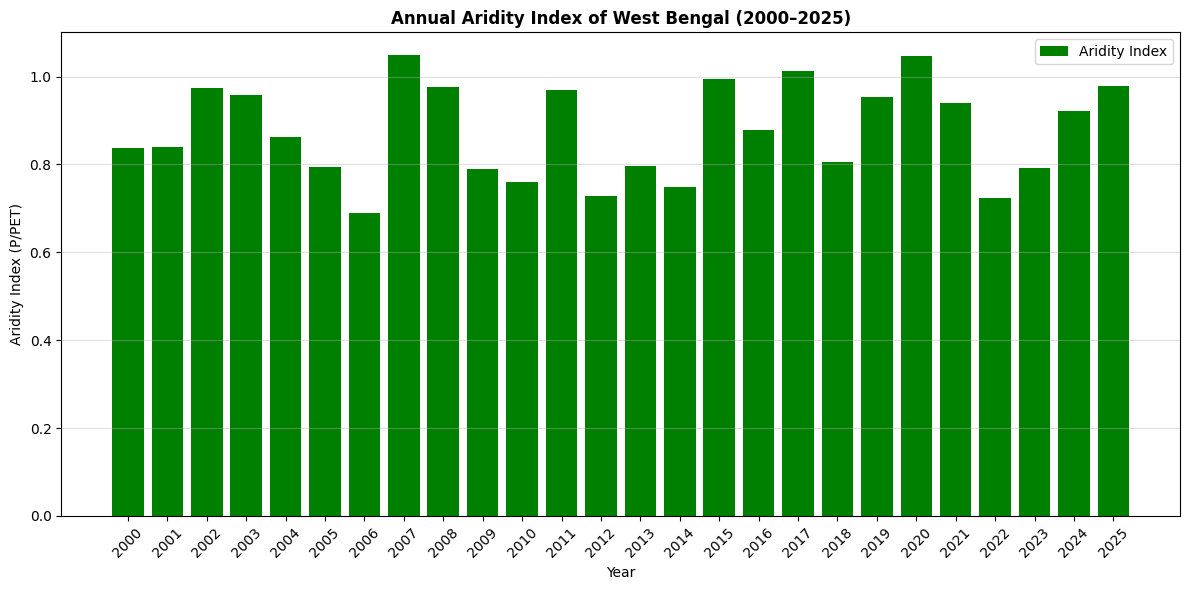

In [243]:
plt.figure(figsize=(12, 6))

plt.bar(
    annual_aridity_index.index,
    annual_aridity_index.values,
    color = 'green',
    label = "Aridity Index"
)

plt.title(
    'Annual Aridity Index of West Bengal (2000–2025)',
    fontweight='bold'
)

plt.xlabel('Year')
plt.ylabel('Aridity Index (P/PET)')
plt.xticks(annual_aridity_index.index, rotation=45)
plt.grid(axis='y', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

# **Calculate Corelation between temparature and Actual Evaporation**

In [244]:
# Calculate corelation and p_value
correlation, p_value = pearsonr(
    annual_temp['annual_mean_temp_C'],
    annual_evap['annual_evaporation_mm']
)

# Calculate Trend line
temp = annual_temp['annual_mean_temp_C'].to_numpy()
evap = annual_evap['annual_evaporation_mm'].to_numpy()

slope, intercept = np.polyfit(
    temp,
    evap,
    1
)

trend_line = slope * temp + intercept


# print all statistical value and interpretation
print(f"Pearson Correlation Coefficient: {round(correlation, 3)}")

if correlation == 1:
    interpretation = "Perfect Positive Correlation"

elif correlation >= 0.70:
    interpretation = "Strong Positive Correlation"

elif correlation >= 0.30:
    interpretation = "Moderate Positive Correlation"

elif correlation > 0:
    interpretation = "Weak Positive Correlation"

elif correlation == 0:
    interpretation = "No Linear Correlation"

elif correlation > -0.30:
    interpretation = "Weak Negative Correlation"

elif correlation > -0.70:
    interpretation = "Moderate Negative Correlation"

elif correlation > -1:
    interpretation = "Strong Negative Correlation"

else:
    interpretation = "Perfect Negative Correlation"

print("Interpretation:", interpretation)


print(f"P-value: {round(p_value, 2)}")

if p_value < 0.05:
    significance = "Statistically Significant"
else:
    significance = "Not Statistically Significant"

print("Statistical Significance:", significance)

Pearson Correlation Coefficient: -0.244
Interpretation: Weak Negative Correlation
P-value: 0.23
Statistical Significance: Not Statistically Significant


# **Visualize temperature and Evaporation relationship**

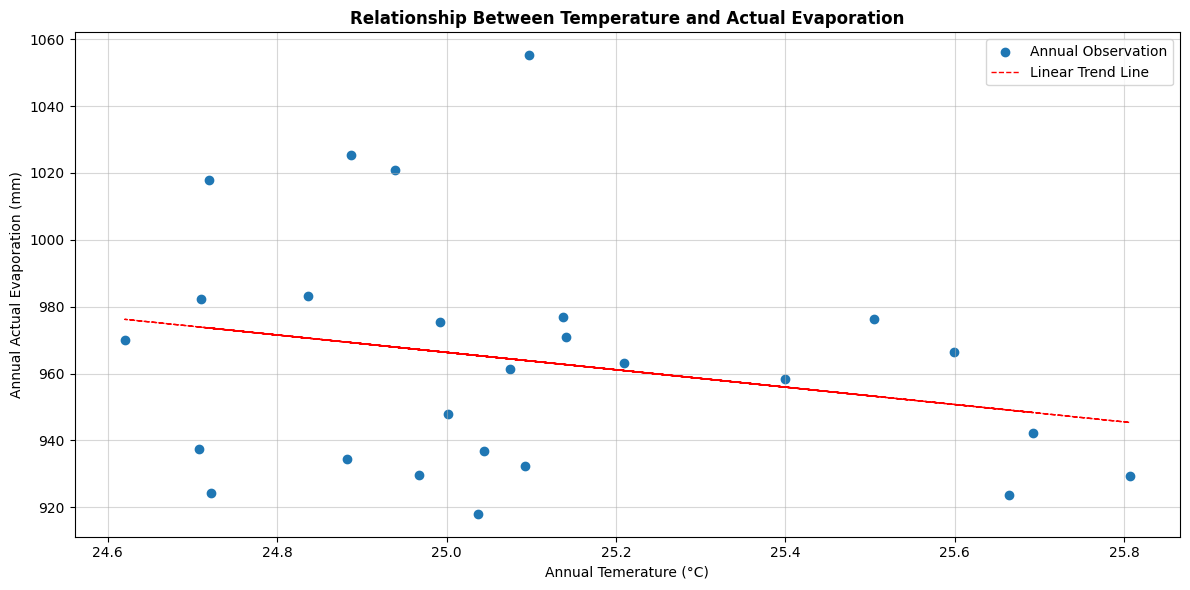

In [245]:

plt.figure(figsize= (12, 6))

plt.scatter(
    annual_temp['annual_mean_temp_C'],
    annual_evap['annual_evaporation_mm'],
    label = "Annual Observation"
)

plt.plot(
    annual_temp['annual_mean_temp_C'],
    trend_line,
    label = 'Linear Trend Line',
    color = 'red',
    linestyle = '--',
    linewidth = 1
)

plt.title(
    "Relationship Between Temperature and Actual Evaporation",
    fontweight = 'bold'
)

plt.xlabel('Annual Temerature (°C)')
plt.ylabel('Annual Actual Evaporation (mm)')

plt.tight_layout()
plt.grid(True, alpha = 0.5)
plt.legend()
plt.show()

# **Calculate Corelation between Actual Evaporation and Potential Evaporation**

In [246]:
# Calculation for correlation and p_ value
correlation, p_value = pearsonr(
    annual_evap['annual_evaporation_mm'],
    annual_evap['annual_potential_evaporation_mm']
)

# Calculate Trend line
actual_evap = annual_evap['annual_evaporation_mm'].to_numpy()
potential_evap = annual_evap['annual_potential_evaporation_mm'].to_numpy()

slope, intercept = np.polyfit(actual_evap, potential_evap, 1)

trend_line = slope * actual_evap + intercept

# print all statistical value and interpretation
print(f"Pearson Correlation Coefficient: {round(correlation, 3)}")

if correlation == 1:
    interpretation = "Perfect Positive Correlation"

elif correlation >= 0.70:
    interpretation = "Strong Positive Correlation"

elif correlation >= 0.30:
    interpretation = "Moderate Positive Correlation"

elif correlation > 0:
    interpretation = "Weak Positive Correlation"

elif correlation == 0:
    interpretation = "No Linear Correlation"

elif correlation > -0.30:
    interpretation = "Weak Negative Correlation"

elif correlation > -0.70:
    interpretation = "Moderate Negative Correlation"

elif correlation > -1:
    interpretation = "Strong Negative Correlation"

else:
    interpretation = "Perfect Negative Correlation"

print("Interpretation:", interpretation)


print(f"P-value: {round(p_value, 2)}")

if p_value < 0.05:
    significance = "Statistically Significant"
else:
    significance = "Not Statistically Significant"

print("Statistical Significance:", significance)

Pearson Correlation Coefficient: -0.492
Interpretation: Moderate Negative Correlation
P-value: 0.01
Statistical Significance: Statistically Significant


# **Visualize relationship between Actual Evaporation and Potential Evaporation**

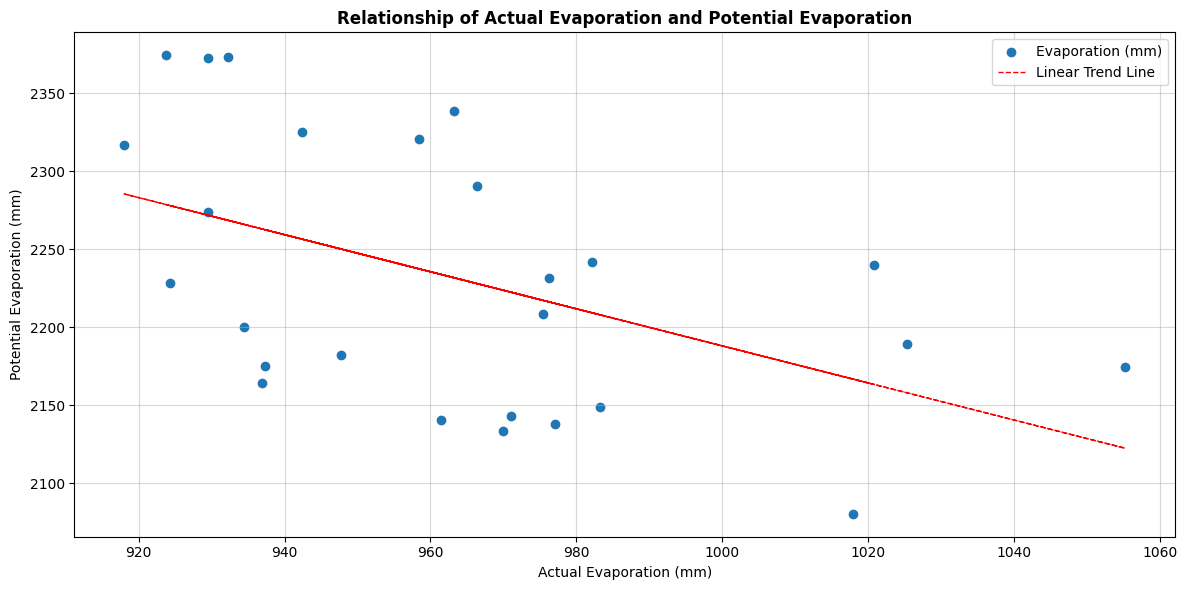

In [247]:
plt.figure(figsize=(12, 6))

plt.scatter(
    actual_evap,
    potential_evap,
    label = "Evaporation (mm)"
)

plt.plot(
    actual_evap,
    trend_line,
    label = "Linear Trend Line",
    color = 'red',
    linestyle = '--',
    linewidth = 1
)

plt.title(
    "Relationship of Actual Evaporation and Potential Evaporation",
    fontweight = 'bold'
)

plt.xlabel('Actual Evaporation (mm)')
plt.ylabel('Potential Evaporation (mm)')


plt.grid(True, alpha = 0.5)
plt.tight_layout()
plt.legend()
plt.show()

# **Climate Correlation Analysis**

# **Select the climate variables:**

In [248]:
climate_columns = [
    'annual_mean_temp_C',
    'annual_precipitation_mm',
    'annual_relative_humidity_pct',
    'annual_wind_speed_m_s',
    'annual_evaporation_mm',
    'annual_potential_evaporation_mm']

# Keep required columns
climate_df = df[
    ["longitude", "latitude", "year"] + climate_columns
].copy()

display(climate_df)

,longitude,latitude,year,annual_mean_temp_C,annual_precipitation_mm,annual_relative_humidity_pct,annual_wind_speed_m_s,annual_evaporation_mm,annual_potential_evaporation_mm
0,86.454785,23.479879,2000,24.733728,930.001497,65.298855,1.655146,935.155419,2498.468287
1,87.536680,23.075908,2000,25.293916,1298.261598,71.541403,1.713750,1030.400276,2117.805414
2,89.453581,26.174277,2000,23.937583,3368.055709,74.341909,1.477707,925.637645,1895.449467
3,89.367415,26.349956,2000,23.686228,3090.336606,72.085653,1.179465,899.477260,1764.328547
4,87.289156,21.871953,2000,25.754289,1221.950740,73.145766,2.095899,1080.629801,2446.206696
...,...,...,...,...,...,...,...,...,...
77423,88.258746,24.116809,2025,25.555062,1546.616785,73.428386,1.873298,1025.754847,1993.566364
77424,88.311510,26.730749,2025,22.878751,2945.333502,78.040349,0.733350,941.862790,1654.867470
77425,86.967219,23.115585,2025,25.385564,1864.630751,70.882055,1.721516,949.273231,2124.851234
77426,88.101207,25.292380,2025,24.956738,1635.313279,74.279536,1.737055,946.780497,2229.098909


# **Calculate annual average of all climate variables**

In [249]:
annual_climate = (
    climate_df.groupby("year")[climate_columns]
    .mean()
    .reset_index()
)

display(annual_climate.head())


,year,annual_mean_temp_C,annual_precipitation_mm,annual_relative_humidity_pct,annual_wind_speed_m_s,annual_evaporation_mm,annual_potential_evaporation_mm
0,2000,24.710332,1785.945388,71.990022,1.697104,982.190603,2241.483957
1,2001,24.707681,1773.318464,72.436242,1.651960,937.337934,2175.050698
2,2002,24.836599,1982.743544,73.671324,1.668518,983.268855,2148.962113
3,2003,24.620037,1904.489272,74.806931,1.741705,969.991306,2133.742580
4,2004,24.967907,1816.449428,71.704509,1.815862,929.547063,2274.071871


# **Calculate Pearson correlation matrix table**

In [250]:
correlation_matrix = annual_climate[climate_columns].corr(
    method="pearson"
)

print("Climate Correlation Matrix:")
display(correlation_matrix.round(3))

Climate Correlation Matrix:


,annual_mean_temp_C,annual_precipitation_mm,annual_relative_humidity_pct,annual_wind_speed_m_s,annual_evaporation_mm,annual_potential_evaporation_mm
annual_mean_temp_C,1.000,-0.190,-0.441,0.112,-0.244,0.648
annual_precipitation_mm,-0.190,1.000,0.560,-0.453,0.182,-0.653
annual_relative_humidity_pct,-0.441,0.560,1.000,-0.127,0.665,-0.885
annual_wind_speed_m_s,0.112,-0.453,-0.127,1.000,-0.068,0.418
annual_evaporation_mm,-0.244,0.182,0.665,-0.068,1.000,-0.492
annual_potential_evaporation_mm,0.648,-0.653,-0.885,0.418,-0.492,1.000


# **Climate correlation of all veriable**

In [251]:
# Function to interpret correlation values
def interpret_correlation(r):

    if r >= 0.70:
        return "Strong Positive Correlation"

    elif r >= 0.30:
        return "Moderate Positive Correlation"

    elif r > 0:
        return "Weak Positive Correlation"

    elif r == 0:
        return "No Linear Correlation"

    elif r > -0.30:
        return "Weak Negative Correlation"

    elif r > -0.70:
        return "Moderate Negative Correlation"

    else:
        return "Strong Negative Correlation"


# Convert correlation matrix into variable pairs
correlation_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Correlation"
]


# Add interpretation column
correlation_pairs["Interpretation"] = (
    correlation_pairs["Correlation"]
    .apply(interpret_correlation)
)


# Print interpretation

print("CLIMATE CORRELATION INTERPRETATION")
print("=" * 70)

for _, row in correlation_pairs.iterrows():

    print(f"\nVariable 1: {row['Variable_1']}")
    print(f"Variable 2: {row['Variable_2']}")
    print(f"Correlation: {row['Correlation']:.3f}")
    print(f"Interpretation: {row['Interpretation']}")
    print("-" * 70)

CLIMATE CORRELATION INTERPRETATION

Variable 1: annual_mean_temp_C
Variable 2: annual_precipitation_mm
Correlation: -0.190
Interpretation: Weak Negative Correlation
----------------------------------------------------------------------

Variable 1: annual_mean_temp_C
Variable 2: annual_relative_humidity_pct
Correlation: -0.441
Interpretation: Moderate Negative Correlation
----------------------------------------------------------------------

Variable 1: annual_mean_temp_C
Variable 2: annual_wind_speed_m_s
Correlation: 0.112
Interpretation: Weak Positive Correlation
----------------------------------------------------------------------

Variable 1: annual_mean_temp_C
Variable 2: annual_evaporation_mm
Correlation: -0.244
Interpretation: Weak Negative Correlation
----------------------------------------------------------------------

Variable 1: annual_mean_temp_C
Variable 2: annual_potential_evaporation_mm
Correlation: 0.648
Interpretation: Moderate Positive Correlation
----------------

# **Visualize the correlation matrix**

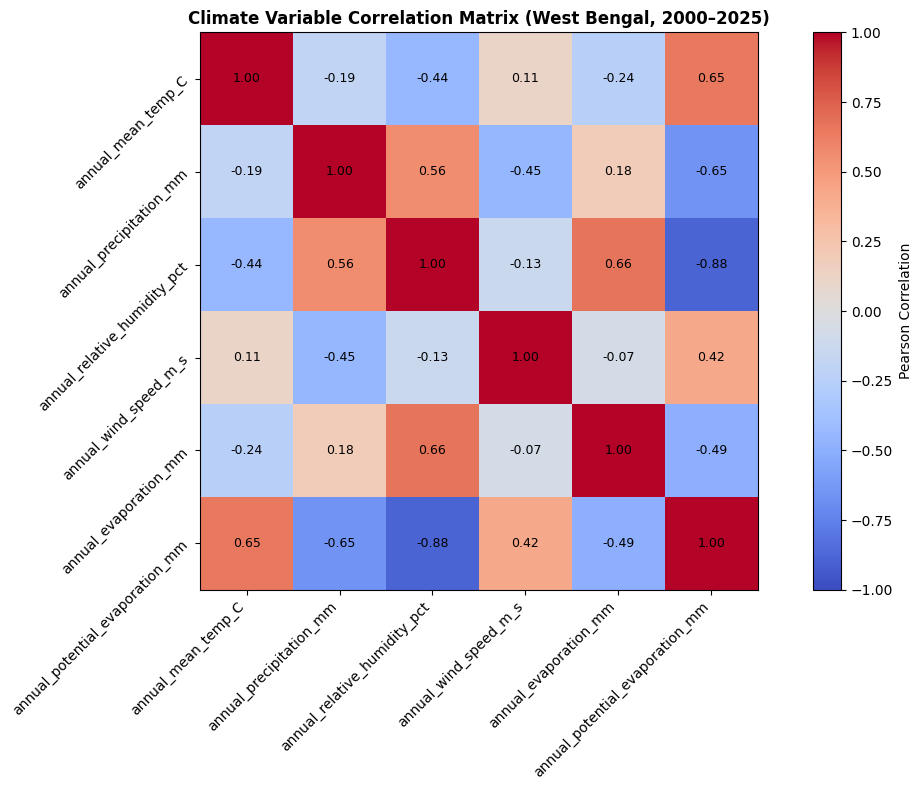

In [252]:
plt.figure(figsize=(12, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Add colorbar
plt.colorbar(label="Pearson Correlation")

# Add variable names
plt.xticks(
    range(len(climate_columns)),
    climate_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(climate_columns)),
    climate_columns,
    rotation=45
)

# Display correlation values
for i in range(len(climate_columns)):
    for j in range(len(climate_columns)):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

plt.title(
    "Climate Variable Correlation Matrix (West Bengal, 2000–2025)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# **Wind speed analysis**

# **Select Wind Speed Column**

In [253]:
wind_speed = df['annual_wind_speed_m_s']

print(wind_speed.head())

0    1.655146
1    1.713750
2    1.477707
3    1.179465
4    2.095899
Name: annual_wind_speed_m_s, dtype: float64


# **Calculate Long term Mean and Standard Deviation of wind speed**

In [254]:
mean_wind_speed = wind_speed.mean()
print(f"Long term Average wind speed: {round(mean_wind_speed, 2)} m/s")

std_wind_speed = wind_speed.std()
print(f"Standard Deviation of wind speed: {round(std_wind_speed, 2)}")

Long term Average wind speed: 1.71 m/s
Standard Deviation of wind speed: 0.49


# **Calculate average wind speed for every year from 2000 to 2025.**

In [255]:
annual_wind = (
    df.groupby('year')['annual_wind_speed_m_s']
    .mean()
    .reset_index()
)

display(annual_wind)

,year,annual_wind_speed_m_s
0,2000,1.697104
1,2001,1.651960
2,2002,1.668518
3,2003,1.741705
4,2004,1.815862
5,2005,1.797849
6,2006,1.684294
7,2007,1.704597
8,2008,1.654085
9,2009,1.715097


# **Visualize annual wind speed**

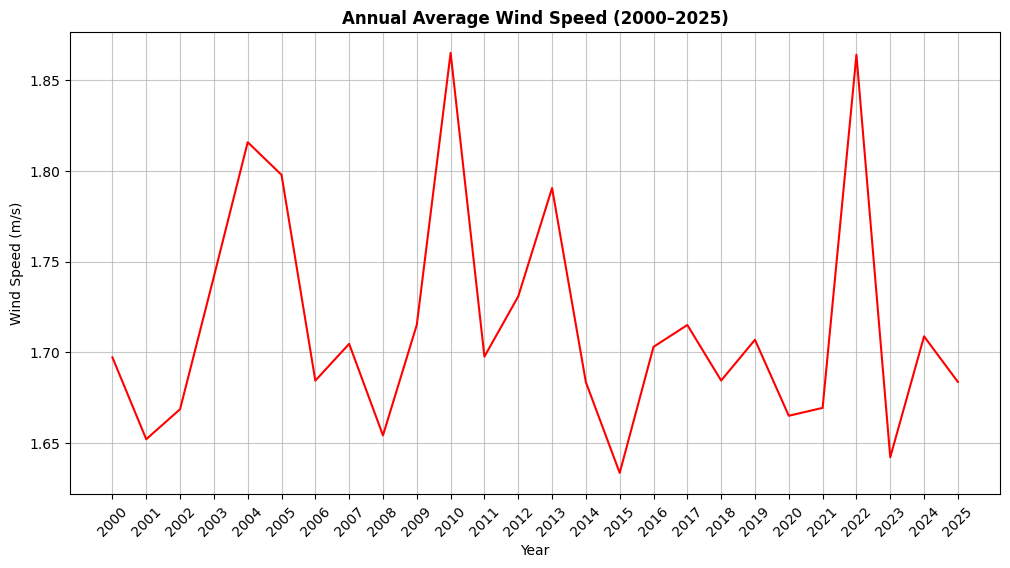

In [256]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_wind['year'],
    annual_wind['annual_wind_speed_m_s'],
    color = 'red'
)

plt.title(
    "Annual Average Wind Speed (2000–2025)",
    fontweight = 'bold'
)

plt.xlabel("Year")
plt.ylabel("Wind Speed (m/s)")

plt.xticks(annual_wind['year'], rotation = 45)
plt.grid(True, alpha = 0.7)
plt.show()

# **Annual Wind run calculation**


**Wind Run = Wind Speed X Time**

**WR= (Wind Speed X times X 365 X 24 X 3600)**




In [257]:
annual_wind['annual_wind_run_km'] = (
    annual_wind['annual_wind_speed_m_s'] * 365 * 24 * 3600 / 1000
)

display(
    annual_wind[
        ['year',
         'annual_wind_speed_m_s',
         'annual_wind_run_km']
        ]
)

,year,annual_wind_speed_m_s,annual_wind_run_km
0,2000,1.697104,53519.872616
1,2001,1.651960,52096.210575
2,2002,1.668518,52618.370740
3,2003,1.741705,54926.402388
4,2004,1.815862,57265.026921
5,2005,1.797849,56696.972774
6,2006,1.684294,53115.894952
7,2007,1.704597,53756.171129
8,2008,1.654085,52163.232547
9,2009,1.715097,54087.284512


# **Wind direction analysis**

# **Convert wind direction into compass directions**

In [258]:
directions = [
    'N', 'NNE', 'NE', 'ENE',
    'E', 'ESE', 'SE', 'SSE',
    'S', 'SSW', 'SW', 'WSW',
    'W', 'WNW', 'NW', 'NNW'
]

# Convert wind direction degrees into 16 compass directions
directions_index = (
    ((df['annual_wind_direction_deg'] + 11.25) % 360) / 22.5
).astype(int)

df['wind_direction_class'] = np.array(directions)[directions_index.to_numpy()]

display(df['wind_direction_class'])



,wind_direction_class
0,SSW
1,SSW
2,SSE
3,S
4,SSW
...,...
77423,SSW
77424,E
77425,SSW
77426,SSW


# **Calculate prevailing wind direction**

In [259]:
prevailing_direction = (
    df['wind_direction_class'].mode()[0]
)

print("Prevailing Wind Direction:", prevailing_direction)

Prevailing Wind Direction: SSW


# **For Year 2025**

In [260]:
df_2025 = df[df['year'] == 2025].copy()

prevailing_2025 = (
    df_2025['wind_direction_class'].mode()[0]
)

print("2025 Prevailing Wind Direction:", prevailing_2025)

2025 Prevailing Wind Direction: SSW


# **Visualize a wind rose Diagram for wind direction and Wind Speed**

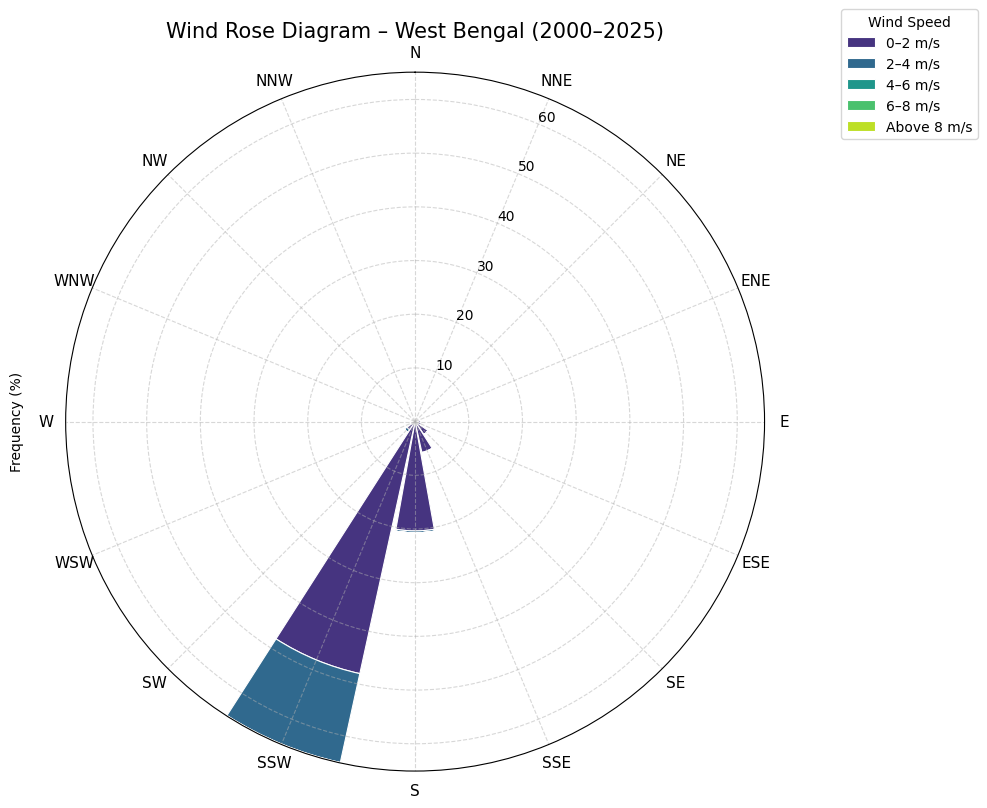

In [261]:
# Convert degrees into directional sector indices
direction_index = (
    np.floor(
        (df["annual_wind_direction_deg"].values
         + (22.5 / 2)) / 22.5
    ).astype(int) % 16
)

#  Define wind speed categories


speed_bins = [0, 2, 4, 6, 8, np.inf]

speed_labels = [
    "0–2 m/s",
    "2–4 m/s",
    "4–6 m/s",
    "6–8 m/s",
    "Above 8 m/s"
]

speed_index = pd.cut(
    df["annual_wind_speed_m_s"],
    bins=speed_bins,
    labels=False,
    right=False
)

# Remove observations outside speed bins
valid = speed_index.notna()

direction_index = direction_index[valid.to_numpy()]
speed_index = speed_index[valid].astype(int).to_numpy()

#  Calculate frequency
frequency = np.zeros(
    (16, len(speed_labels))
)

for d, s in zip(direction_index, speed_index):
    frequency[d, s] += 1

# Convert frequency into percentage
frequency_percent = (
    frequency / frequency.sum()
) * 100

# Create Wind Rose Diagram
fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"projection": "polar"}
)

# Set North at the top
ax.set_theta_zero_location("N")

# Set clockwise direction
ax.set_theta_direction(-1)

# Direction angles in radians
theta = np.deg2rad(
    np.arange(16) * 22.5
)

# Bar width
bar_width = np.deg2rad(22.5 * 0.9)

# Stacked bars
bottom = np.zeros(16)

colors = plt.cm.viridis(
    np.linspace(0.15, 0.9, len(speed_labels))
)

for i, label in enumerate(speed_labels):

    ax.bar(
        theta,
        frequency_percent[:, i],
        width=bar_width,
        bottom=bottom,
        color=colors[i],
        edgecolor="white",
        linewidth=0.8,
        label=label,
        align="center"
    )

    bottom += frequency_percent[:, i]

# Customize diagram
ax.set_xticks(theta)
ax.set_xticklabels(directions, fontsize=11)

ax.set_title(
    "Wind Rose Diagram – West Bengal (2000–2025)",
    fontsize=15,
    pad=25
)

ax.set_ylabel("Frequency (%)", labelpad=30)

ax.grid(True, linestyle="--", alpha=0.5)

ax.legend(
    title="Wind Speed",
    loc="upper left",
    bbox_to_anchor=(1.1, 1.1)
)

plt.tight_layout()
plt.show()